In [ ]:
# Set working directory
setwd("E:/MB_Bulk_RNA_seq/Post_Analysis_script")

# Core tidyverse and data manipulation
library(dplyr)
library(tidyr)
library(purrr)
library(readr)
library(data.table)

# Genomic data structures and annotation
library(GenomicFeatures)
library(GenomicRanges) 
library(TxDb.Hsapiens.UCSC.hg38.knownGene)
library(SNPlocs.Hsapiens.dbSNP144.GRCh38)
library(AnnotationHub)
library(org.Hs.eg.db)

# Single-cell and expression analysis
library(SingleCellExperiment)
library(pheatmap)
""
# RAER (RNA editing) analysis
library(raer)
source("../Analysis_script/REDITs/REDIT_LLR.R")

# Enrichment and pathway analysis
library(DOSE)
library(clusterProfiler)
library(enrichplot)

# Visualization
library(ggplot2)
library(glue)


Warning message:
"package 'dplyr' was built under R version 4.4.3"

Attaching package: 'dplyr'


The following objects are masked from 'package:stats':

    filter, lag


The following objects are masked from 'package:base':

    intersect, setdiff, setequal, union


Warning message:
"package 'readr' was built under R version 4.4.3"
Warning message:
"package 'data.table' was built under R version 4.4.3"

Attaching package: 'data.table'


The following object is masked from 'package:purrr':

    transpose


The following objects are masked from 'package:dplyr':

    between, first, last


Loading required package: BiocGenerics


Attaching package: 'BiocGenerics'


The following objects are masked from 'package:dplyr':

    combine, intersect, setdiff, union


The following objects are masked from 'package:stats':

    IQR, mad, sd, var, xtabs


The following objects are masked from 'package:base':

    anyDuplicated, aperm, append, as.data.frame, basename, cbind,
    colnames, dirname, 

[1] ""

Warning message:
"package 'DOSE' was built under R version 4.4.3"


DOSE v4.0.1 Learn more at https://yulab-smu.top/contribution-knowledge-mining/

Please cite:

Guangchuang Yu, Li-Gen Wang, Guang-Rong Yan, Qing-Yu He. DOSE: an
R/Bioconductor package for Disease Ontology Semantic and Enrichment
analysis. Bioinformatics. 2015, 31(4):608-609

Warning message:
"package 'clusterProfiler' was built under R version 4.4.2"
clusterProfiler v4.14.6 Learn more at https://yulab-smu.top/contribution-knowledge-mining/

Please cite:

Guangchuang Yu, Li-Gen Wang, Yanyan Han and Qing-Yu He.
clusterProfiler: an R package for comparing biological themes among
gene clusters. OMICS: A Journal of Integrative Biology. 2012,
16(5):284-287


Attaching package: 'clusterProfiler'


The following object is masked from 'package:XVector':

    slice


The following object is masked from 'package:AnnotationDbi':

    select


The following object is masked from 'package:IRanges':

    slice


The following object i

# Grp3 vs rest

In [ ]:
SHH_Alt = read.csv("H:/Bulk_medulloblastoma_A_to_I_editing_finalized/ICGC_Only_Analysis/data/new_filtered_sites_ICGC_only/SHH_Alt.csv",row.names = 'X')
G4_Alt = read.csv("H:/Bulk_medulloblastoma_A_to_I_editing_finalized/ICGC_Only_Analysis/data/new_filtered_sites_ICGC_only/G4_Alt.csv",row.names = 'X')
G3_Alt = read.csv("H:/Bulk_medulloblastoma_A_to_I_editing_finalized/ICGC_Only_Analysis/data/new_filtered_sites_ICGC_only/G3_Alt.csv",row.names = 'X')
WNT_Alt = read.csv("H:/Bulk_medulloblastoma_A_to_I_editing_finalized/ICGC_Only_Analysis/data/new_filtered_sites_ICGC_only/WNT_Alt.csv",row.names = 'X')
SHH_Ref = read.csv("H:/Bulk_medulloblastoma_A_to_I_editing_finalized/ICGC_Only_Analysis/data/new_filtered_sites_ICGC_only/SHH_Ref.csv",row.names = 'X')
G4_Ref = read.csv("H:/Bulk_medulloblastoma_A_to_I_editing_finalized/ICGC_Only_Analysis/data/new_filtered_sites_ICGC_only/G4_Ref.csv",row.names = 'X')
G3_Ref = read.csv("H:/Bulk_medulloblastoma_A_to_I_editing_finalized/ICGC_Only_Analysis/data/new_filtered_sites_ICGC_only/G3_Ref.csv",row.names = 'X')
WNT_Ref = read.csv("H:/Bulk_medulloblastoma_A_to_I_editing_finalized/ICGC_Only_Analysis/data/new_filtered_sites_ICGC_only/WNT_Ref.csv",row.names = 'X')

In [ ]:
G3_Ref$ID <- rownames(G3_Ref)
G3_Alt$ID <- rownames(G3_Alt)
G4_Ref$ID <- rownames(G4_Ref)
G4_Alt$ID <- rownames(G4_Alt)
SHH_Ref$ID <- rownames(SHH_Ref)
SHH_Alt$ID <- rownames(SHH_Alt)
WNT_Ref$ID <- rownames(WNT_Ref)
WNT_Alt$ID <- rownames(WNT_Alt)

# Merge Ref datasets
G4_WNT_SHH_Ref <- Reduce(function(x, y) merge(x, y, by = "ID"), list(G4_Ref, SHH_Ref, WNT_Ref))
rownames(G4_WNT_SHH_Ref) <- G4_WNT_SHH_Ref$ID
G4_WNT_SHH_Ref <- G4_WNT_SHH_Ref[ , !(names(G4_WNT_SHH_Ref) == "ID") ]

# Merge Alt datasets
G4_WNT_SHH_Alt <- Reduce(function(x, y) merge(x, y, by = "ID"), list(G4_Alt, SHH_Alt, WNT_Alt))
rownames(G4_WNT_SHH_Alt) <- G4_WNT_SHH_Alt$ID
G4_WNT_SHH_Alt <- G4_WNT_SHH_Alt[ , !(names(G4_WNT_SHH_Alt) == "ID") ]


G4_WNT_G3_Ref <- Reduce(function(x, y) merge(x, y, by = "ID"), list(G4_Ref, G3_Ref, WNT_Ref))
rownames(G4_WNT_G3_Ref) <- G4_WNT_G3_Ref$ID
G4_WNT_G3_Ref <- G4_WNT_G3_Ref[ , !(names(G4_WNT_G3_Ref) == "ID") ]

# Merge Alt datasets
G4_WNT_G3_Alt <- Reduce(function(x, y) merge(x, y, by = "ID"), list(G4_Alt, G3_Alt, WNT_Alt))
rownames(G4_WNT_G3_Alt) <- G4_WNT_G3_Alt$ID
G4_WNT_G3_Alt <- G4_WNT_G3_Alt[ , !(names(G4_WNT_G3_Alt) == "ID") ]



G4_G3_Ref <- Reduce(function(x, y) merge(x, y, by = "ID"), list(G3_Ref, G4_Ref))
rownames(G4_G3_Ref) <- G4_G3_Ref$ID
G4_G3_Ref <- G4_G3_Ref[ , !(names(G4_G3_Ref) == "ID") ]

# Merge Alt datasets
G4_G3_Alt <- Reduce(function(x, y) merge(x, y, by = "ID"), list(G3_Alt, G4_Alt))
rownames(G4_G3_Alt) <- G4_G3_Alt$ID
G4_G3_Alt <- G4_G3_Alt[ , !(names(G4_G3_Alt) == "ID") ]

SHH_WNT_G3_Ref <- Reduce(function(x, y) merge(x, y, by = "ID"), list(SHH_Ref, G3_Ref, WNT_Ref))
rownames(SHH_WNT_G3_Ref) <- SHH_WNT_G3_Ref$ID
SHH_WNT_G3_Ref <- SHH_WNT_G3_Ref[ , !(names(SHH_WNT_G3_Ref) == "ID") ]

# Merge Alt datasets
SHH_WNT_G3_Alt <- Reduce(function(x, y) merge(x, y, by = "ID"), list(SHH_Alt, G3_Alt, WNT_Alt))
rownames(SHH_WNT_G3_Alt) <- SHH_WNT_G3_Alt$ID
SHH_WNT_G3_Alt <- SHH_WNT_G3_Alt[ , !(names(SHH_WNT_G3_Alt) == "ID") ]



SHH_G4_G3_Ref <- Reduce(function(x, y) merge(x, y, by = "ID"), list(SHH_Ref, G3_Ref, G4_Ref))
rownames(SHH_G4_G3_Ref) <- SHH_G4_G3_Ref$ID
SHH_G4_G3_Ref <- SHH_G4_G3_Ref[ , !(names(SHH_G4_G3_Ref) == "ID") ]

# Merge Alt datasets
SHH_G4_G3_Alt <- Reduce(function(x, y) merge(x, y, by = "ID"), list(SHH_Alt, G3_Alt, G4_Alt))
rownames(SHH_G4_G3_Alt) <- SHH_G4_G3_Alt$ID
SHH_G4_G3_Alt <- SHH_G4_G3_Alt[ , !(names(SHH_G4_G3_Alt) == "ID") ]




G4_G3_Ref <- Reduce(function(x, y) merge(x, y, by = "ID"), list(G3_Ref, G4_Ref))
rownames(G4_G3_Ref) <- G4_G3_Ref$ID
G4_G3_Ref <- G4_G3_Ref[ , !(names(G4_G3_Ref) == "ID") ]

# Merge Alt datasets
G4_G3_Alt <- Reduce(function(x, y) merge(x, y, by = "ID"), list(G3_Alt, G4_Alt))
rownames(G4_G3_Alt) <- G4_G3_Alt$ID
G4_G3_Alt <- G4_G3_Alt[ , !(names(G4_G3_Alt) == "ID") ]

G3_Alt <- G3_Alt[ , !(names(G3_Alt) == "ID") ]
G3_Ref <- G3_Ref[ , !(names(G3_Ref) == "ID") ]


G4_Alt <- G4_Alt[ , !(names(G4_Alt) == "ID") ]
G4_Ref <- G4_Ref[ , !(names(G4_Ref) == "ID") ]


SHH_Alt <- SHH_Alt[ , !(names(SHH_Alt) == "ID") ]
SHH_Ref <- SHH_Ref[ , !(names(SHH_Ref) == "ID") ]

WNT_Alt <- WNT_Alt[ , !(names(WNT_Alt) == "ID") ]
WNT_Ref <- WNT_Ref[ , !(names(WNT_Ref) == "ID") ]

In [ ]:
freq_WNT = WNT_Alt/(WNT_Alt+WNT_Ref)
freq_WNT[is.na(freq_WNT)] <- 0

freq_SHH = SHH_Alt/(SHH_Alt+SHH_Ref)
freq_SHH[is.na(freq_SHH)] <- 0

In [ ]:
dim(SHH_Alt)[2]+dim(G3_Alt)[2]+dim(G4_Alt)[2]+dim(WNT_Alt)[2]

[1] 170

In [ ]:
Diff_editing <- function(df1_Ref, df1_Alt, df2_Ref, df2_Alt, group1, group2 ) {
    Alt <- merge(df1_Alt, df2_Alt, by = "row.names", all = TRUE)
    Alt[is.na(Alt)] <- 0
    Alt <- Alt[, !names(Alt) %in% c("ID")]
    Ref <- merge(df1_Ref, df2_Ref, by = "row.names", all = TRUE)
    Ref <- Ref[, !names(Ref) %in% c("ID")]


    # Replace NA values with 0
    Ref[is.na(Ref)] <- 0
    rownames(Alt) = Alt$Row.names
    Alt = Alt [,-1]

    rownames(Ref) = Ref$Row.names
    Ref = Ref [,-1]
    a <- rep(c("group1"), each =dim(df1_Alt)[2])
    b <- rep(c("group2"), each=dim(df2_Alt)[2])
    c <- c(a,b)
    # input <- c()
    p_values <- c() 
    # j =1
    for (j in 1:dim(Alt)[1] ){
        #print(j)
        input <- c()
    for (i in 1:dim(Alt)[2]){
        input <- c(input,Alt[j,i] )
        input <- c(input,Ref[j,i] )
        #print(input)
    }
        input = matrix(as.integer(input), nrow=2)
    p_values <- c(p_values, REDIT_LLR(data=input, groups=c)$p.value)}
    adj_P_values <- p.adjust( p_values, method='fdr')
    print("Number of sites with FDR P-value < 0.05")
    print(sum(adj_P_values< 0.05))
    freq = Alt/(Alt+Ref)
    freq[is.na(freq)] <- 0
    freq <- freq +0.01
    freq_G4_WNT_SHH = freq[, (dim(df1_Alt)[2] + 1):(dim(df1_Alt)[2] + dim(df2_Alt)[2])]
    freq_GP3 = freq[,1:dim(df1_Alt)[2]]
    freq_G4_WNT_SHH['G4_WNT_SHH_avg'] = rowMeans(freq_G4_WNT_SHH)
    freq_GP3['G3_avg'] = rowMeans(freq_GP3)

    Alt['p_values'] = p_values
    Alt['adj_p_values'] = adj_P_values
    # Alt['log_fold'] = freq_GP3['GP3_avg']-freq_GP4['GP4_avg']
    Alt['log_fold'] = log2(freq_GP3['G3_avg']/freq_G4_WNT_SHH['G4_WNT_SHH_avg'])
    Alt['Diff_mean'] = freq_GP3['G3_avg']-freq_G4_WNT_SHH['G4_WNT_SHH_avg']
    

    # Your existing code for creating the volcano plot
    log2_fold_change =Alt$Diff_mean
    neg_log10_adj_p_values <- -log10(Alt$adj_p_values)
    adj_p_values <- Alt$adj_p_values
    write.csv(Alt,file = glue("H:/Bulk_medulloblastoma_A_to_I_editing_finalized/ICGC_Only_Analysis/data/Differenitally_edited_sites/Alt_REDIT_{group1}_vs_{group2}_input.txt"))
    # Set plot dimensions
    options(repr.plot.width = 22, repr.plot.height = 12)

    # Adjust graphical parameters
    par(cex.axis = 2, font.axis = 1, cex.lab = 2, font.lab = 1)

    # Increase margin space at the bottom (adjust as needed)
    par(mar = c(5, 5, 4, 7))  # c(bottom, left, top, right)

    # Create the volcano plot
    plot(log2_fold_change, neg_log10_adj_p_values,
        main="",
        xlab=glue("{group1}_avg-{group2}_avg)"),
        ylab="-log10(adjusted p-value)",
        pch=20, col="grey", cex=2)

    # Add significance threshold lines
    abline(h = -log10(0.05), col="black", lty=4)  # Threshold at adjusted p-value 0.05
    abline(v = c(-0.05, 0.05), col="black", lty=4)  # Threshold for log2 fold change

    # Identify significant points
    # significant_points_up <- which(adj_p_values < 0.05 & log2_fold_change > 0.05)
    # significant_points_down <- which(adj_p_values < 0.05 & log2_fold_change < -0.05)
    # significant_points <- which(adj_p_values < 0.05 & abs(log2_fold_change) > 0.05)
    significant_points_up <- which(adj_p_values < 0.05 & log2_fold_change > 0.05)
    significant_points_down <- which(adj_p_values < 0.05 & log2_fold_change < -0.05)
    significant_points <- which(adj_p_values < 0.05 & abs(log2_fold_change) > 0.05)
    # Add colored points for significant findings
    points(log2_fold_change[significant_points_up], 
        neg_log10_adj_p_values[significant_points_up],
        col="red", pch=20, cex=2)

    points(log2_fold_change[significant_points_down], 
        neg_log10_adj_p_values[significant_points_down],
        col="blue", pch=20, cex=2)

    # # Add legend for significant points
    # legend("topright", legend=c("Up-regulated", "Down-regulated"),
    #        col=c("red", "blue"), pch=20, pt.cex=3, text.col="black", cex=1.2, )

    # legend("topright", legend=c("Up-regulated", "Down-regulated"),
    #        col=c("red", "blue"), pch=20, pt.cex=3, text.col="black", cex=1.2,
    #        text.width=0.9, box.lty=0)  # Adjust text.width to make the box smaller
    # Add overall plot title with bold font and increased size
    # title(main="Malignant vs Progenitors cells 2383/51965", 
        #   font.main=1.5, cex.main=2)
    grid()
    # # Alt[c(significant_points_up,significant_points_down),]
    sig_rows <- rownames(Alt[c(significant_points_up,significant_points_down),])

    # Split the row names into components: "chr" and position
    variant_info <- do.call(rbind, strsplit(sig_rows, "_"))
    colnames(variant_info) <- c("Chr", "Start")

    # Convert to a data frame
    wannovar_input <- as.data.frame(variant_info, stringsAsFactors = FALSE)

    # Add 'End', 'Ref', and 'Alt' columns
    wannovar_input$Start <- as.integer(wannovar_input$Start)
    wannovar_input$End <- wannovar_input$Start
    wannovar_input$Ref <- "A"
    wannovar_input$Alt <- "G"

    # Reorder columns for ANNOVAR
    wannovar_input <- wannovar_input[, c("Chr", "Start", "End", "Ref", "Alt")]

    # View or save the result
    head(wannovar_input)
    write.table(wannovar_input, file = glue("H:/Bulk_medulloblastoma_A_to_I_editing_finalized/ICGC_Only_Analysis/data/Differenitally_edited_sites/REDIT_{group1}_vs_{group2}_input.txt"), sep = "\t", quote = FALSE, row.names = FALSE)


    # Combine data correctly
    combined_matrix <- cbind(
    freq_GP3 = freq_GP3[significant_points, -ncol(freq_GP3)],
    freq_G4_WNT_SHH = freq_G4_WNT_SHH[significant_points, -ncol(freq_G4_WNT_SHH)]
    )

    # Convert to matrix
    combined_matrix <- as.matrix(combined_matrix)

    # Scale the rows
    combined_matrix_scaled <- t(scale(t(combined_matrix)))

    # Create annotation
    annotation_col <- data.frame(
    Subtype = factor(c(
        rep(glue("{group1}"), ncol(df1_Alt)),
        rep(glue("{group2}"), ncol(df2_Alt))
    ))
    )
    rownames(annotation_col) <- colnames(combined_matrix)

    # Reorder annotation to match columns (just in case)
    annotation_col <- annotation_col[colnames(combined_matrix), , drop = FALSE]

    # Plot heatmap
    pheatmap(combined_matrix_scaled,
            cluster_rows = TRUE,
            cluster_cols = TRUE,
            annotation_col = annotation_col,
            color = colorRampPalette(c("blue", "white", "red"))(100),
            fontsize_row = 8,
            fontsize_col = 10,
            main = "Heatmap with Subtype Annotation")


    }
# complexheatmap

[1] "Number of sites with FDR P-value < 0.05"
[1] 1703


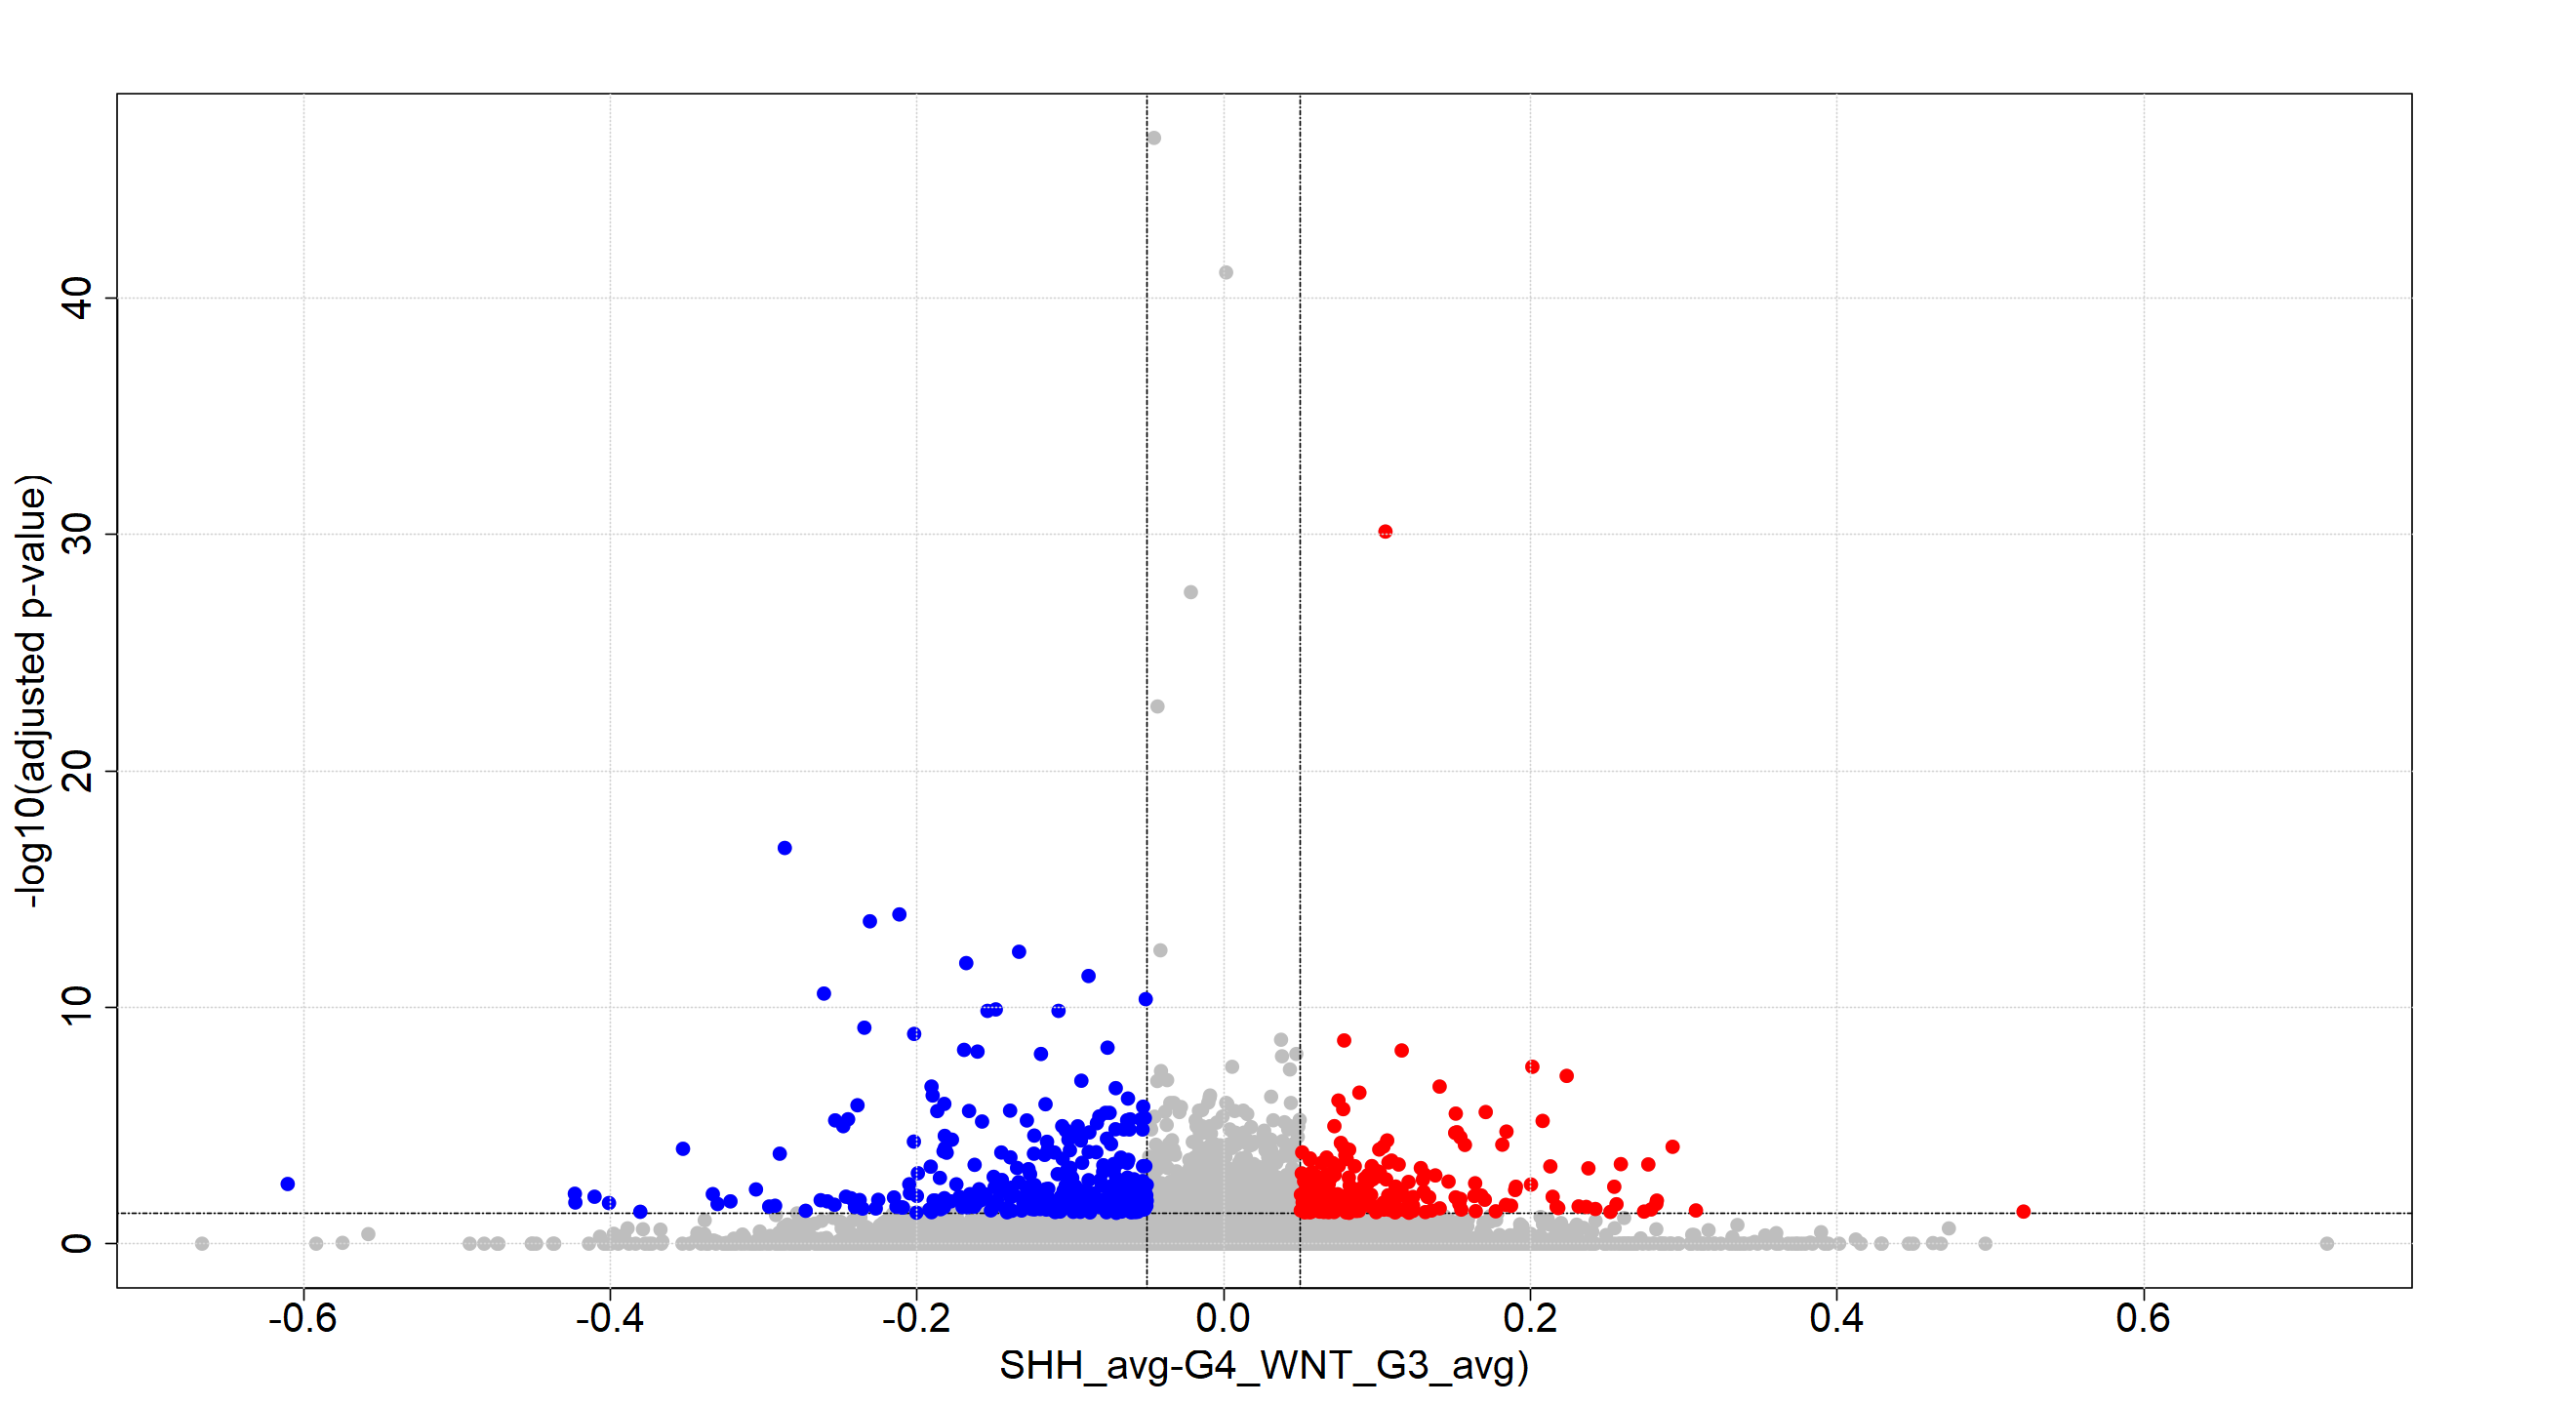

[1] "Number of sites with FDR P-value < 0.05"
[1] 416


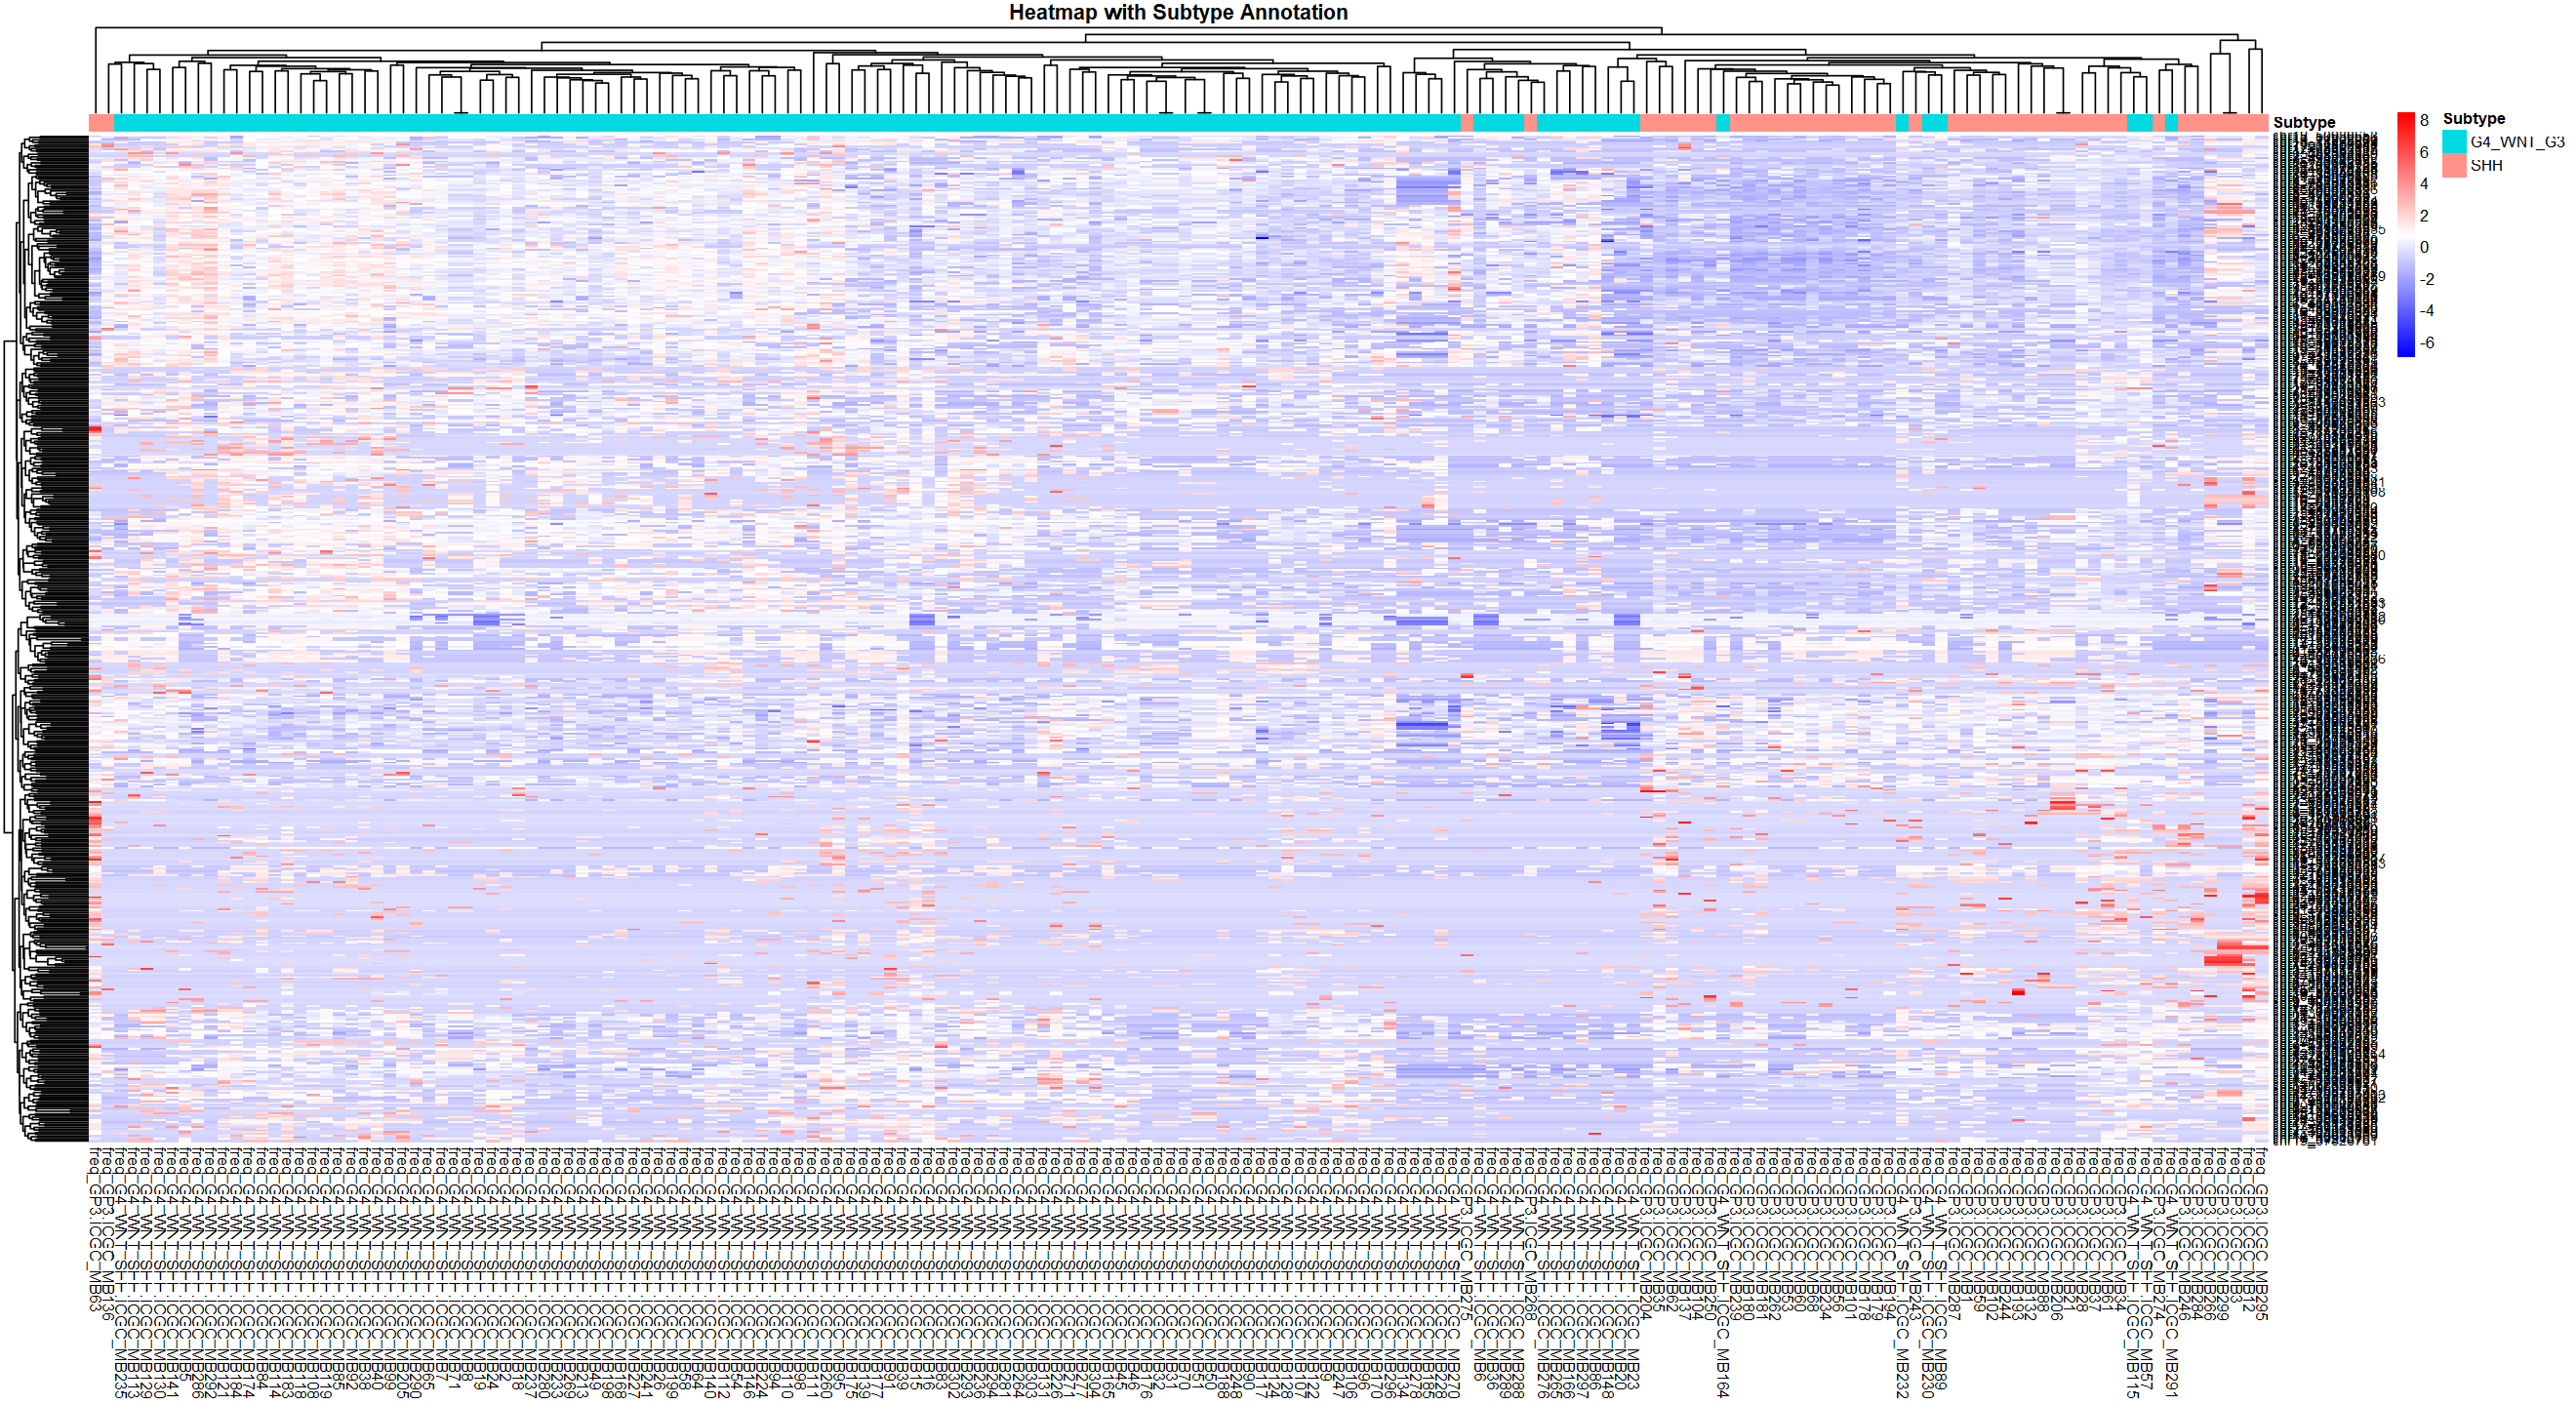

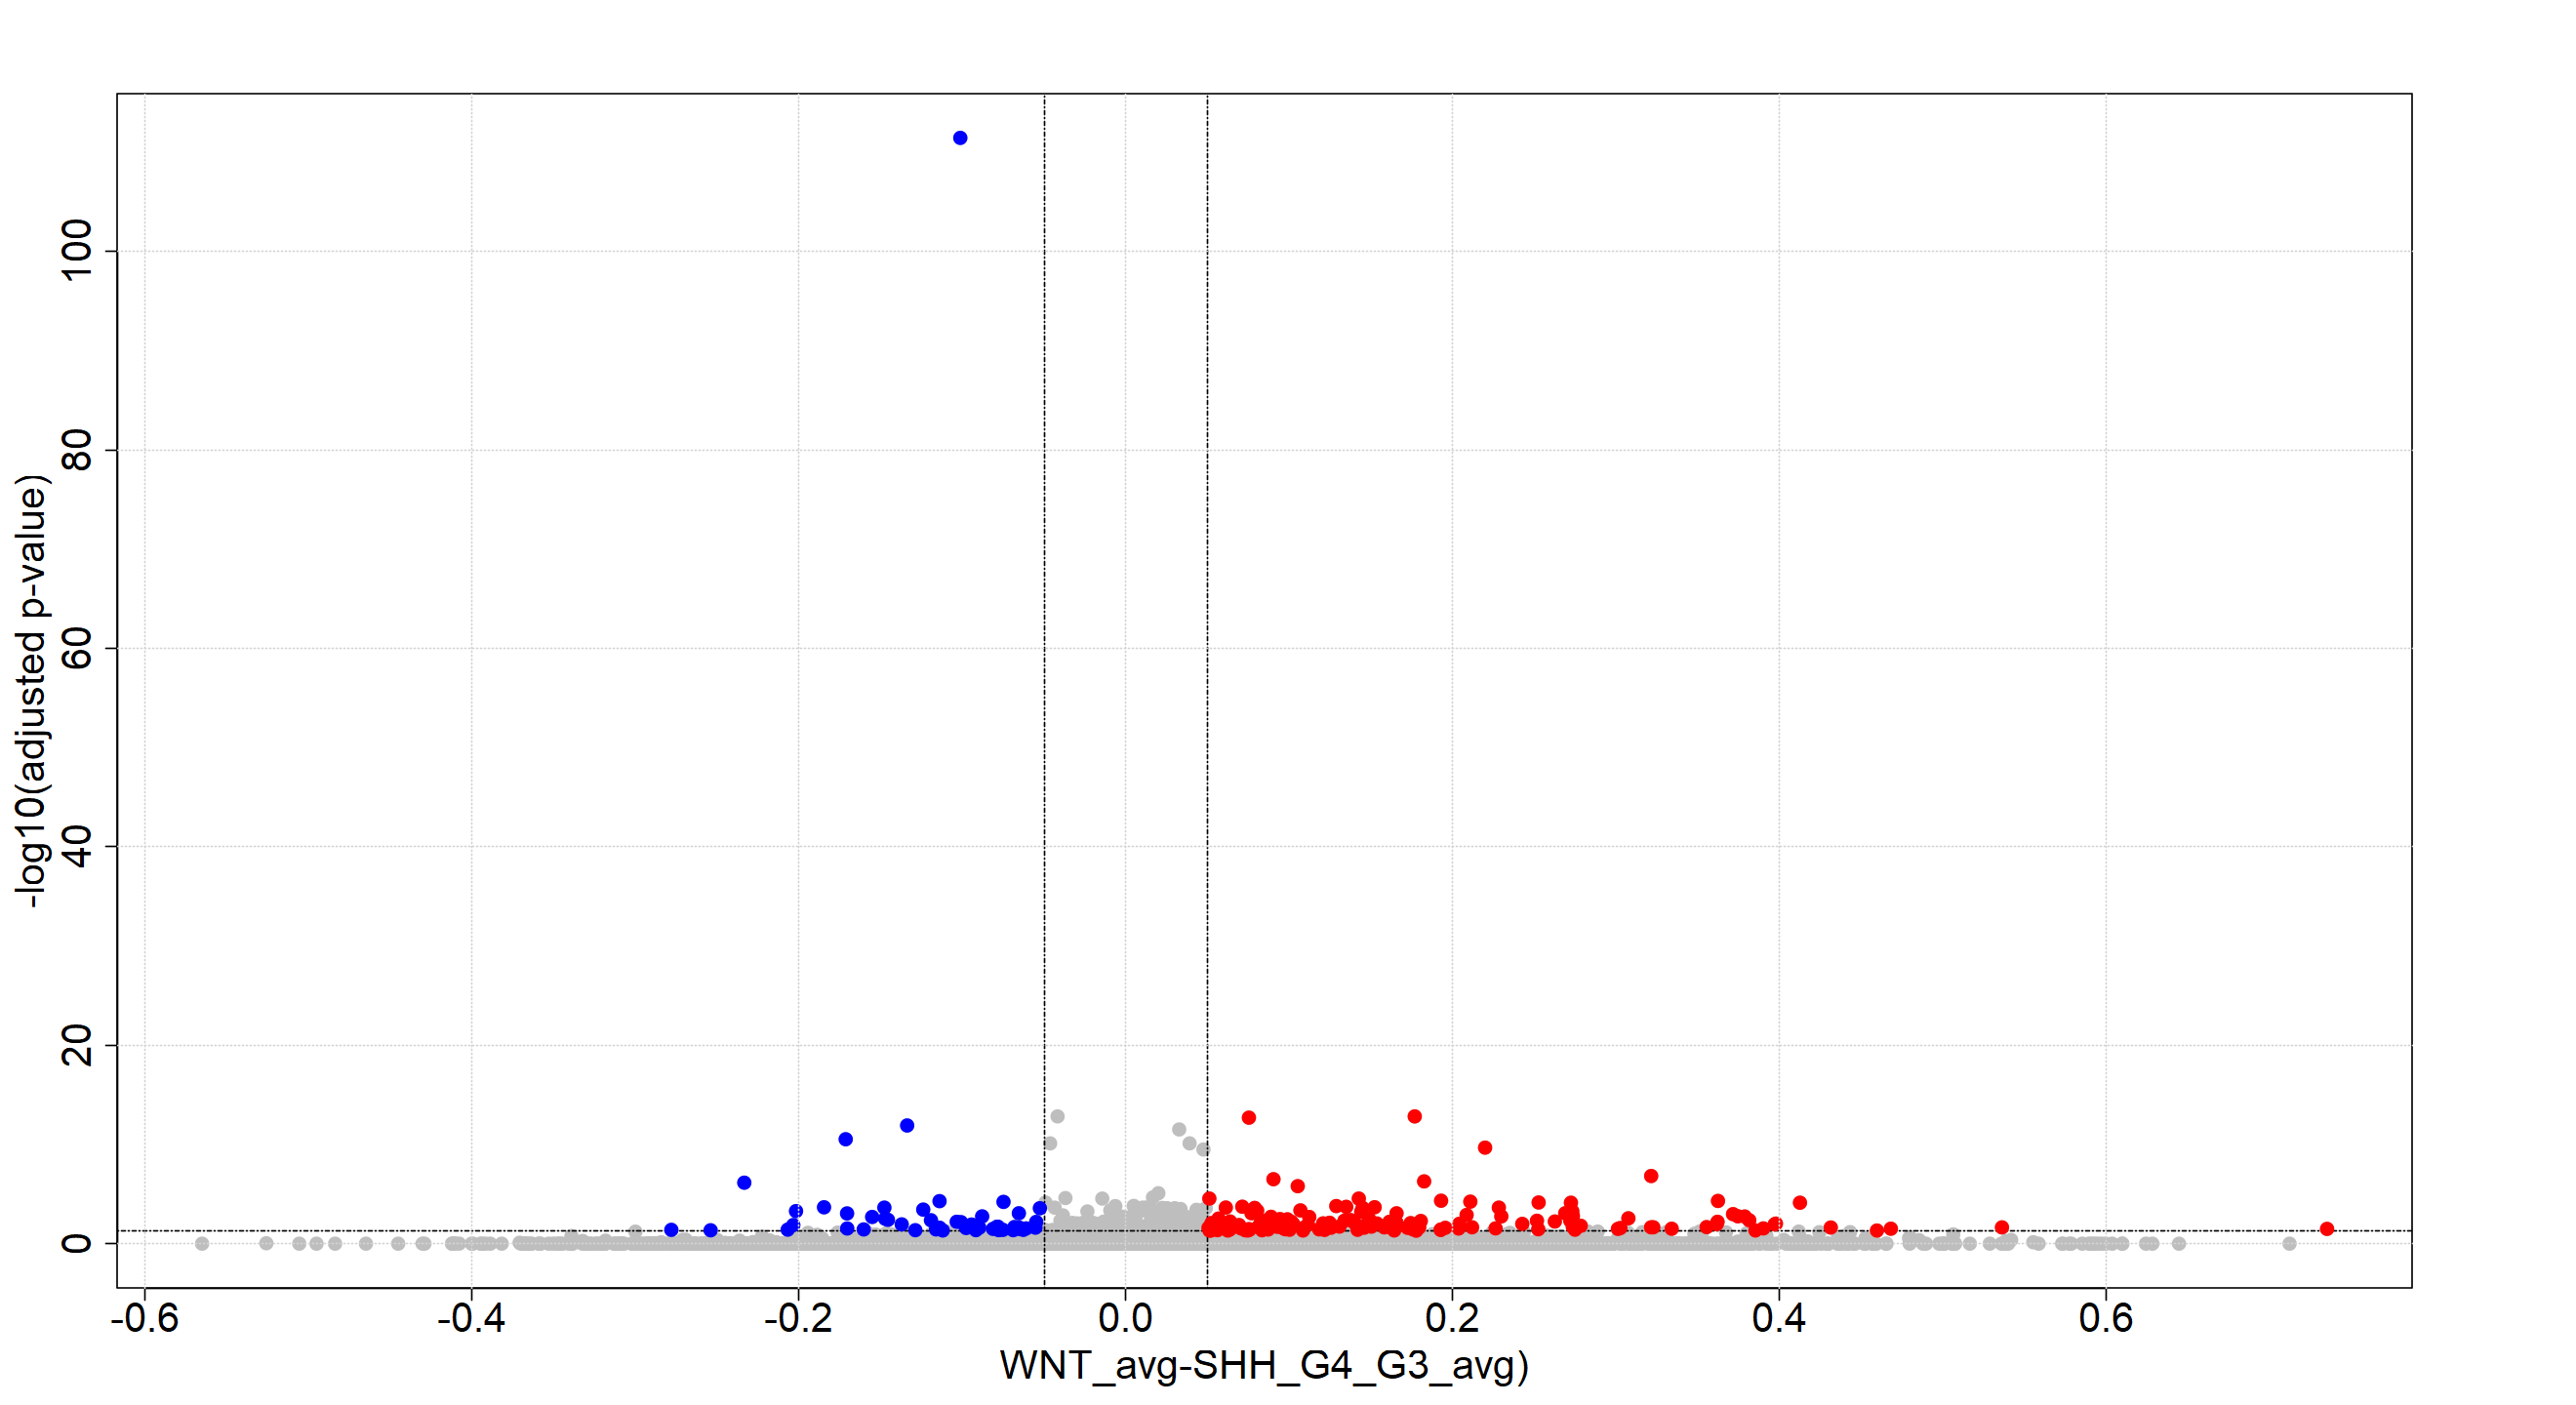

[1] "Number of sites with FDR P-value < 0.05"
[1] 2395


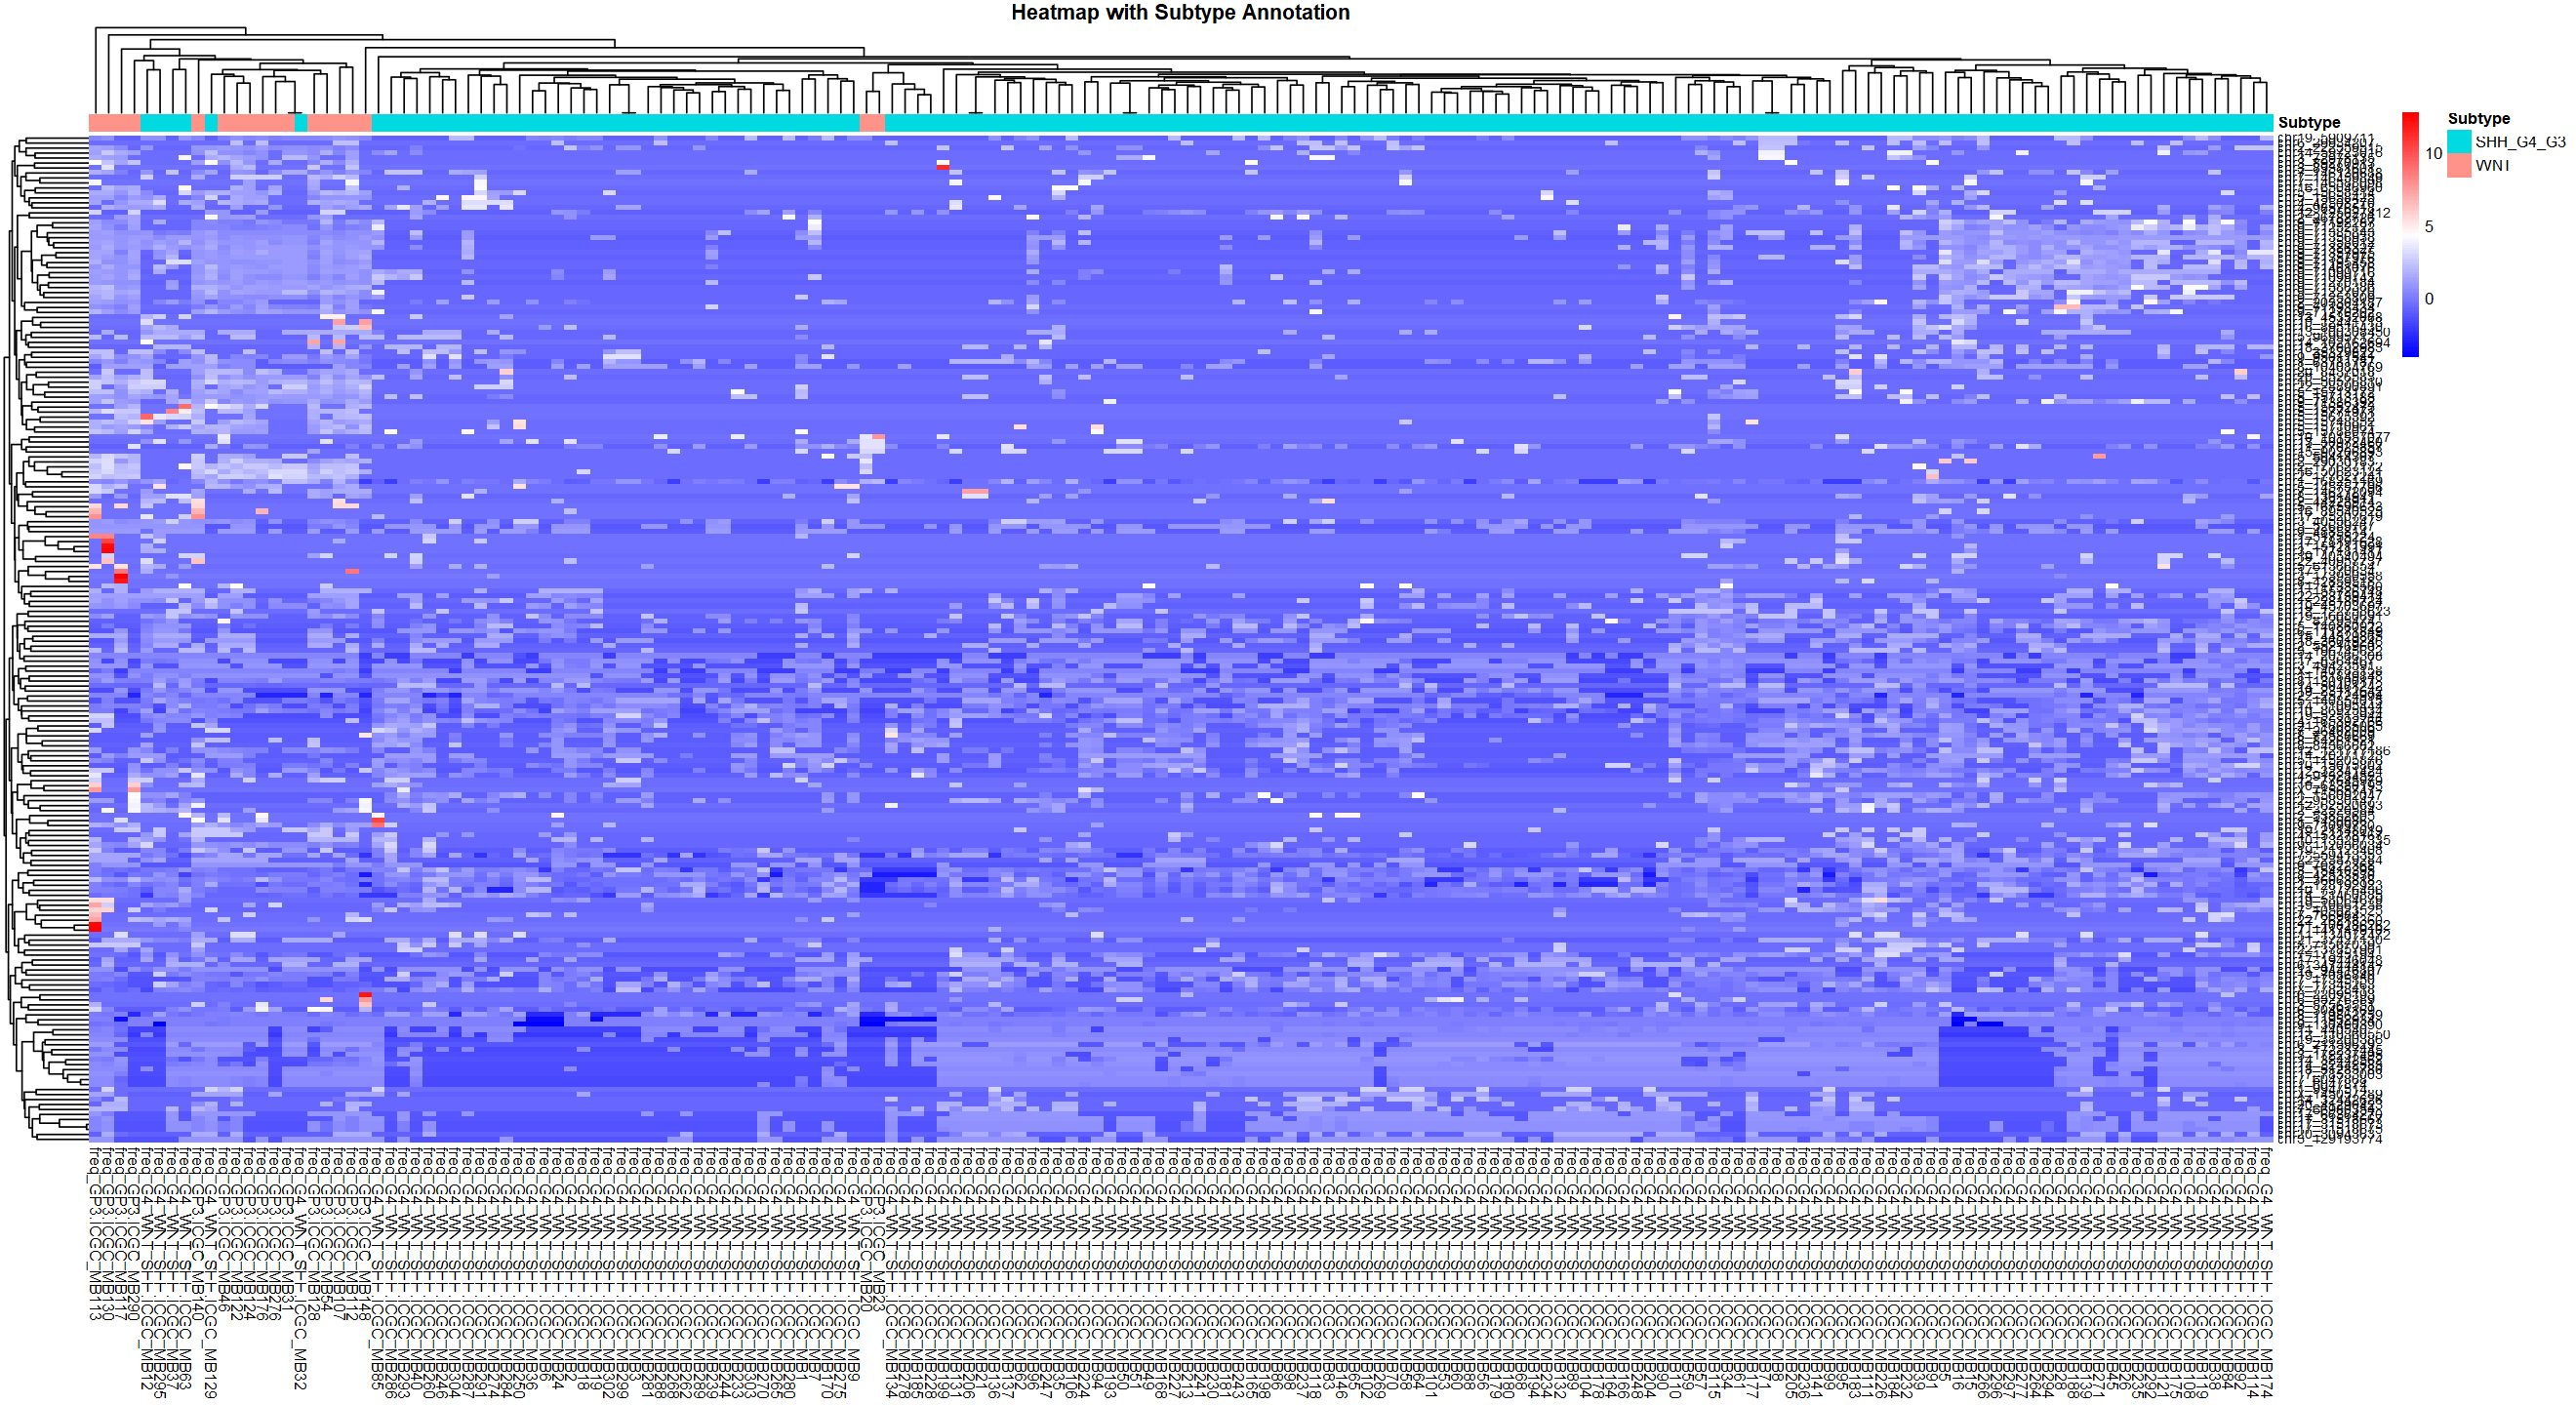

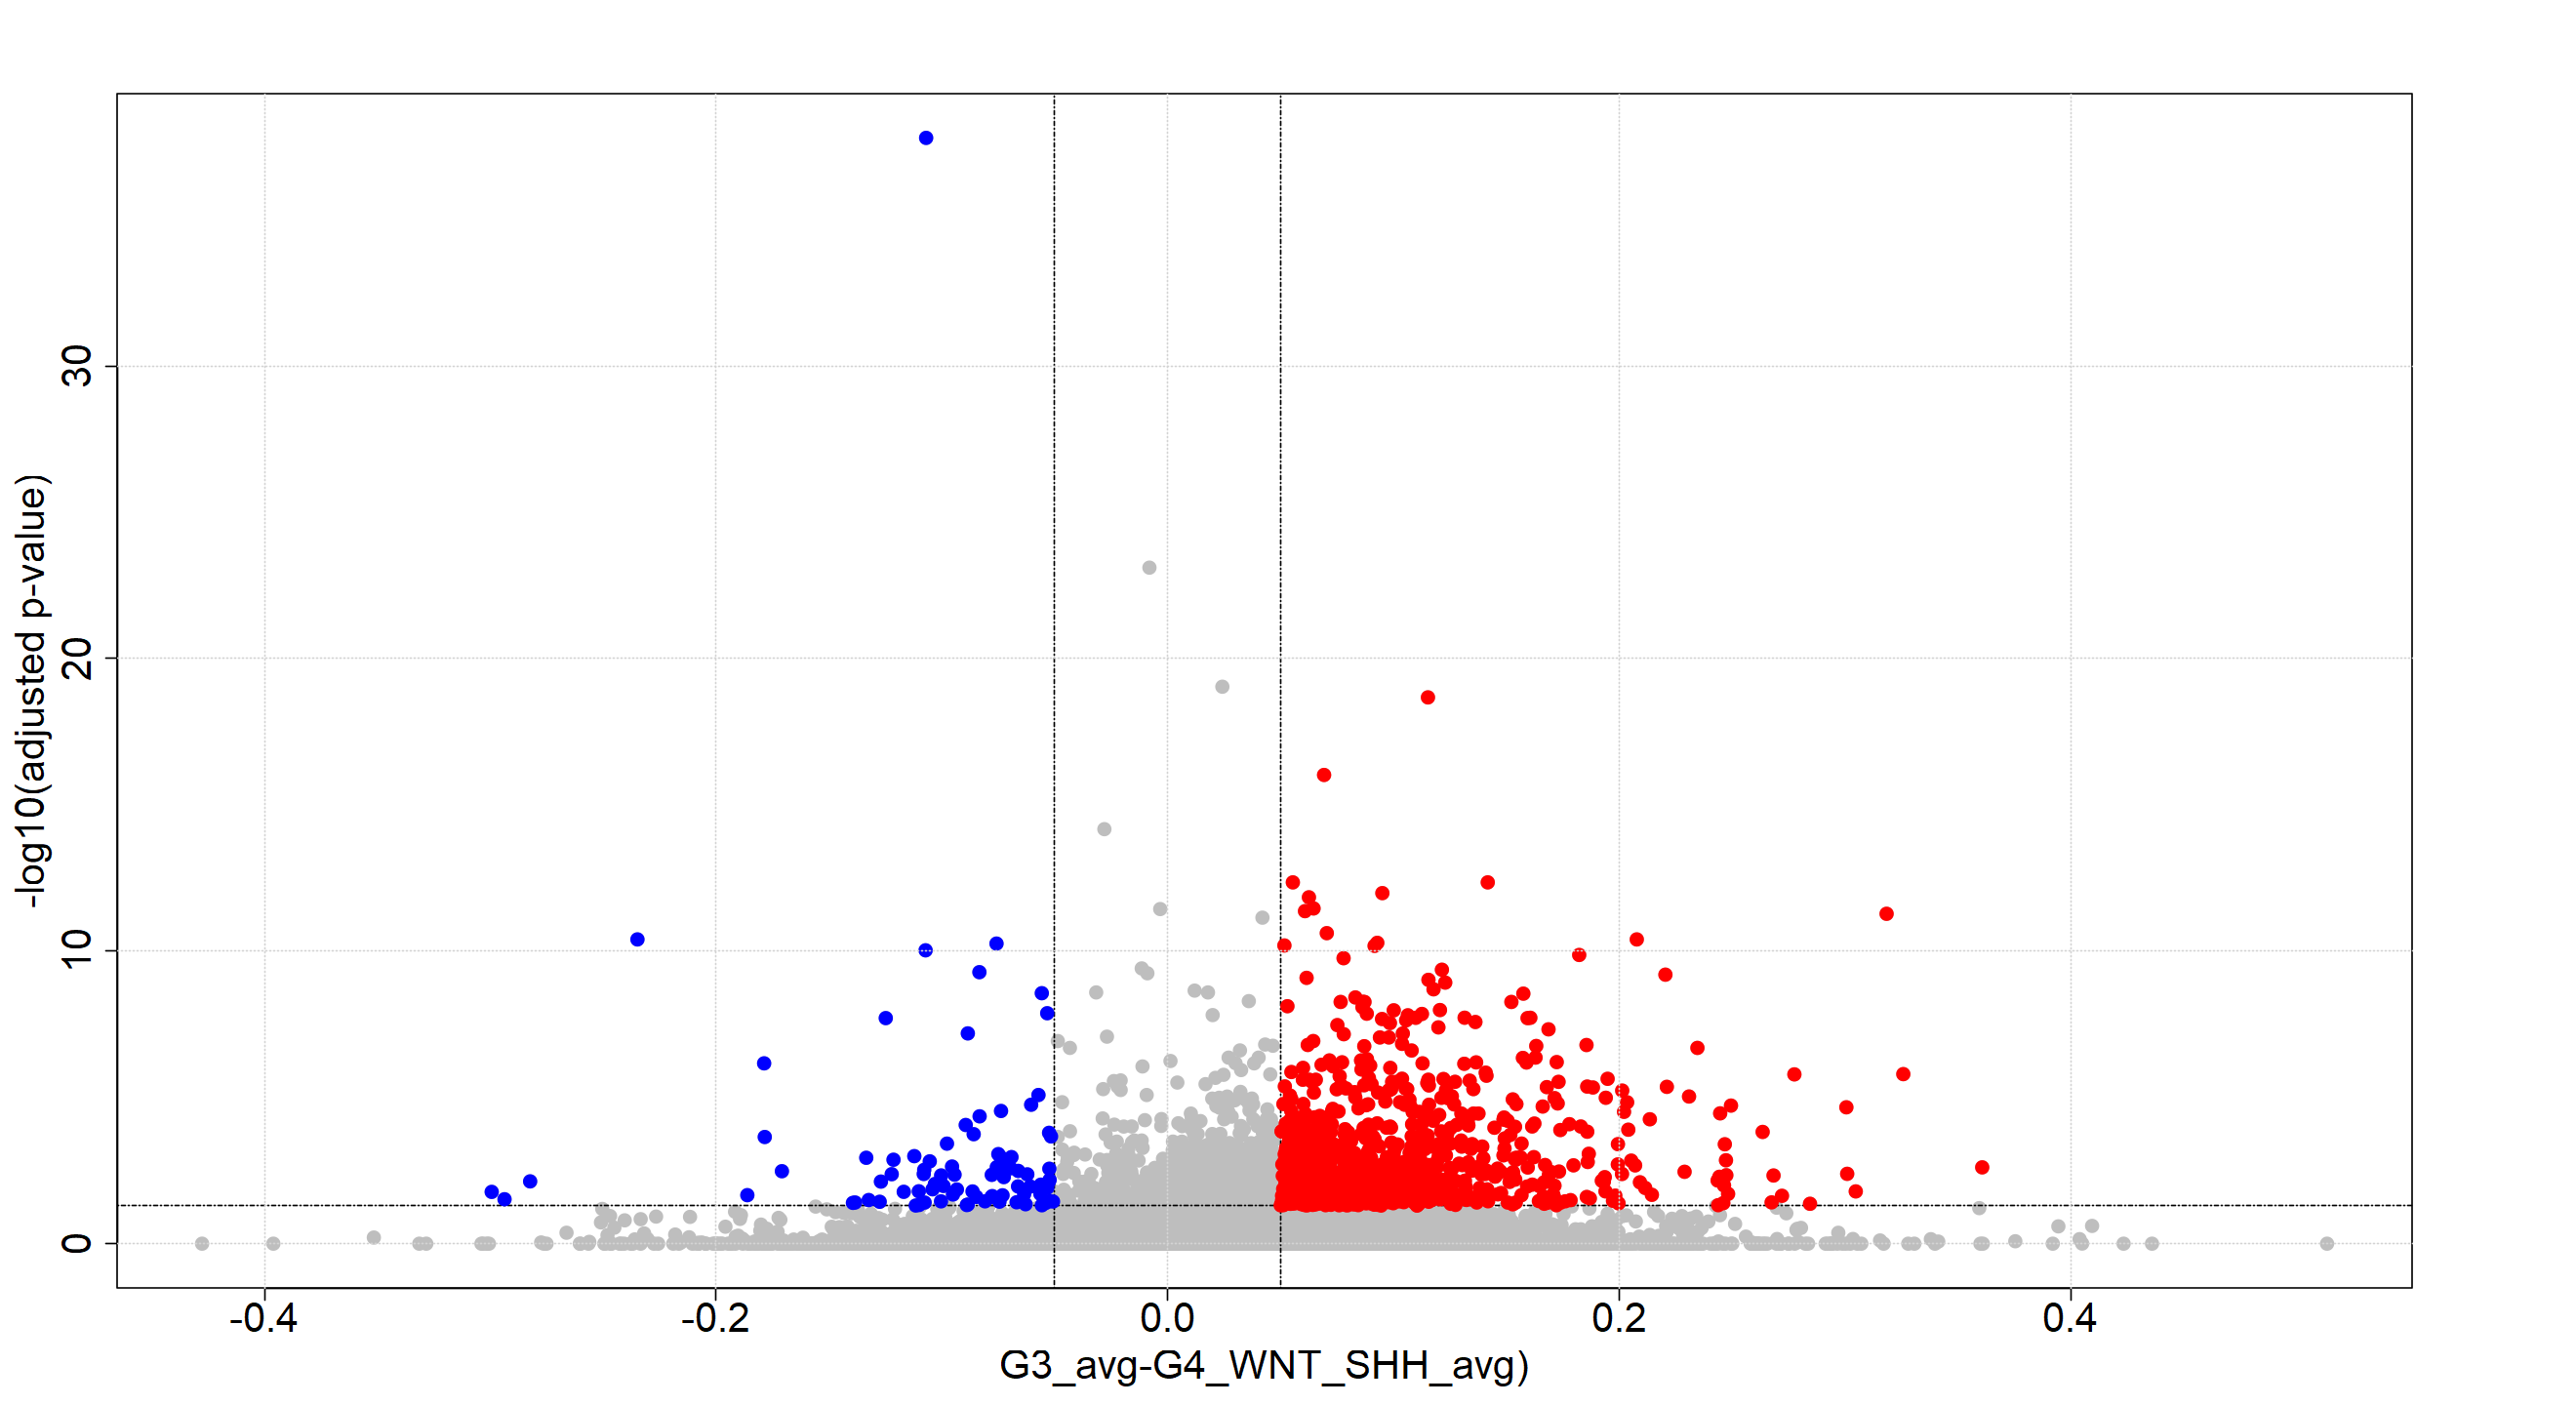

[1] "Number of sites with FDR P-value < 0.05"
[1] 2606


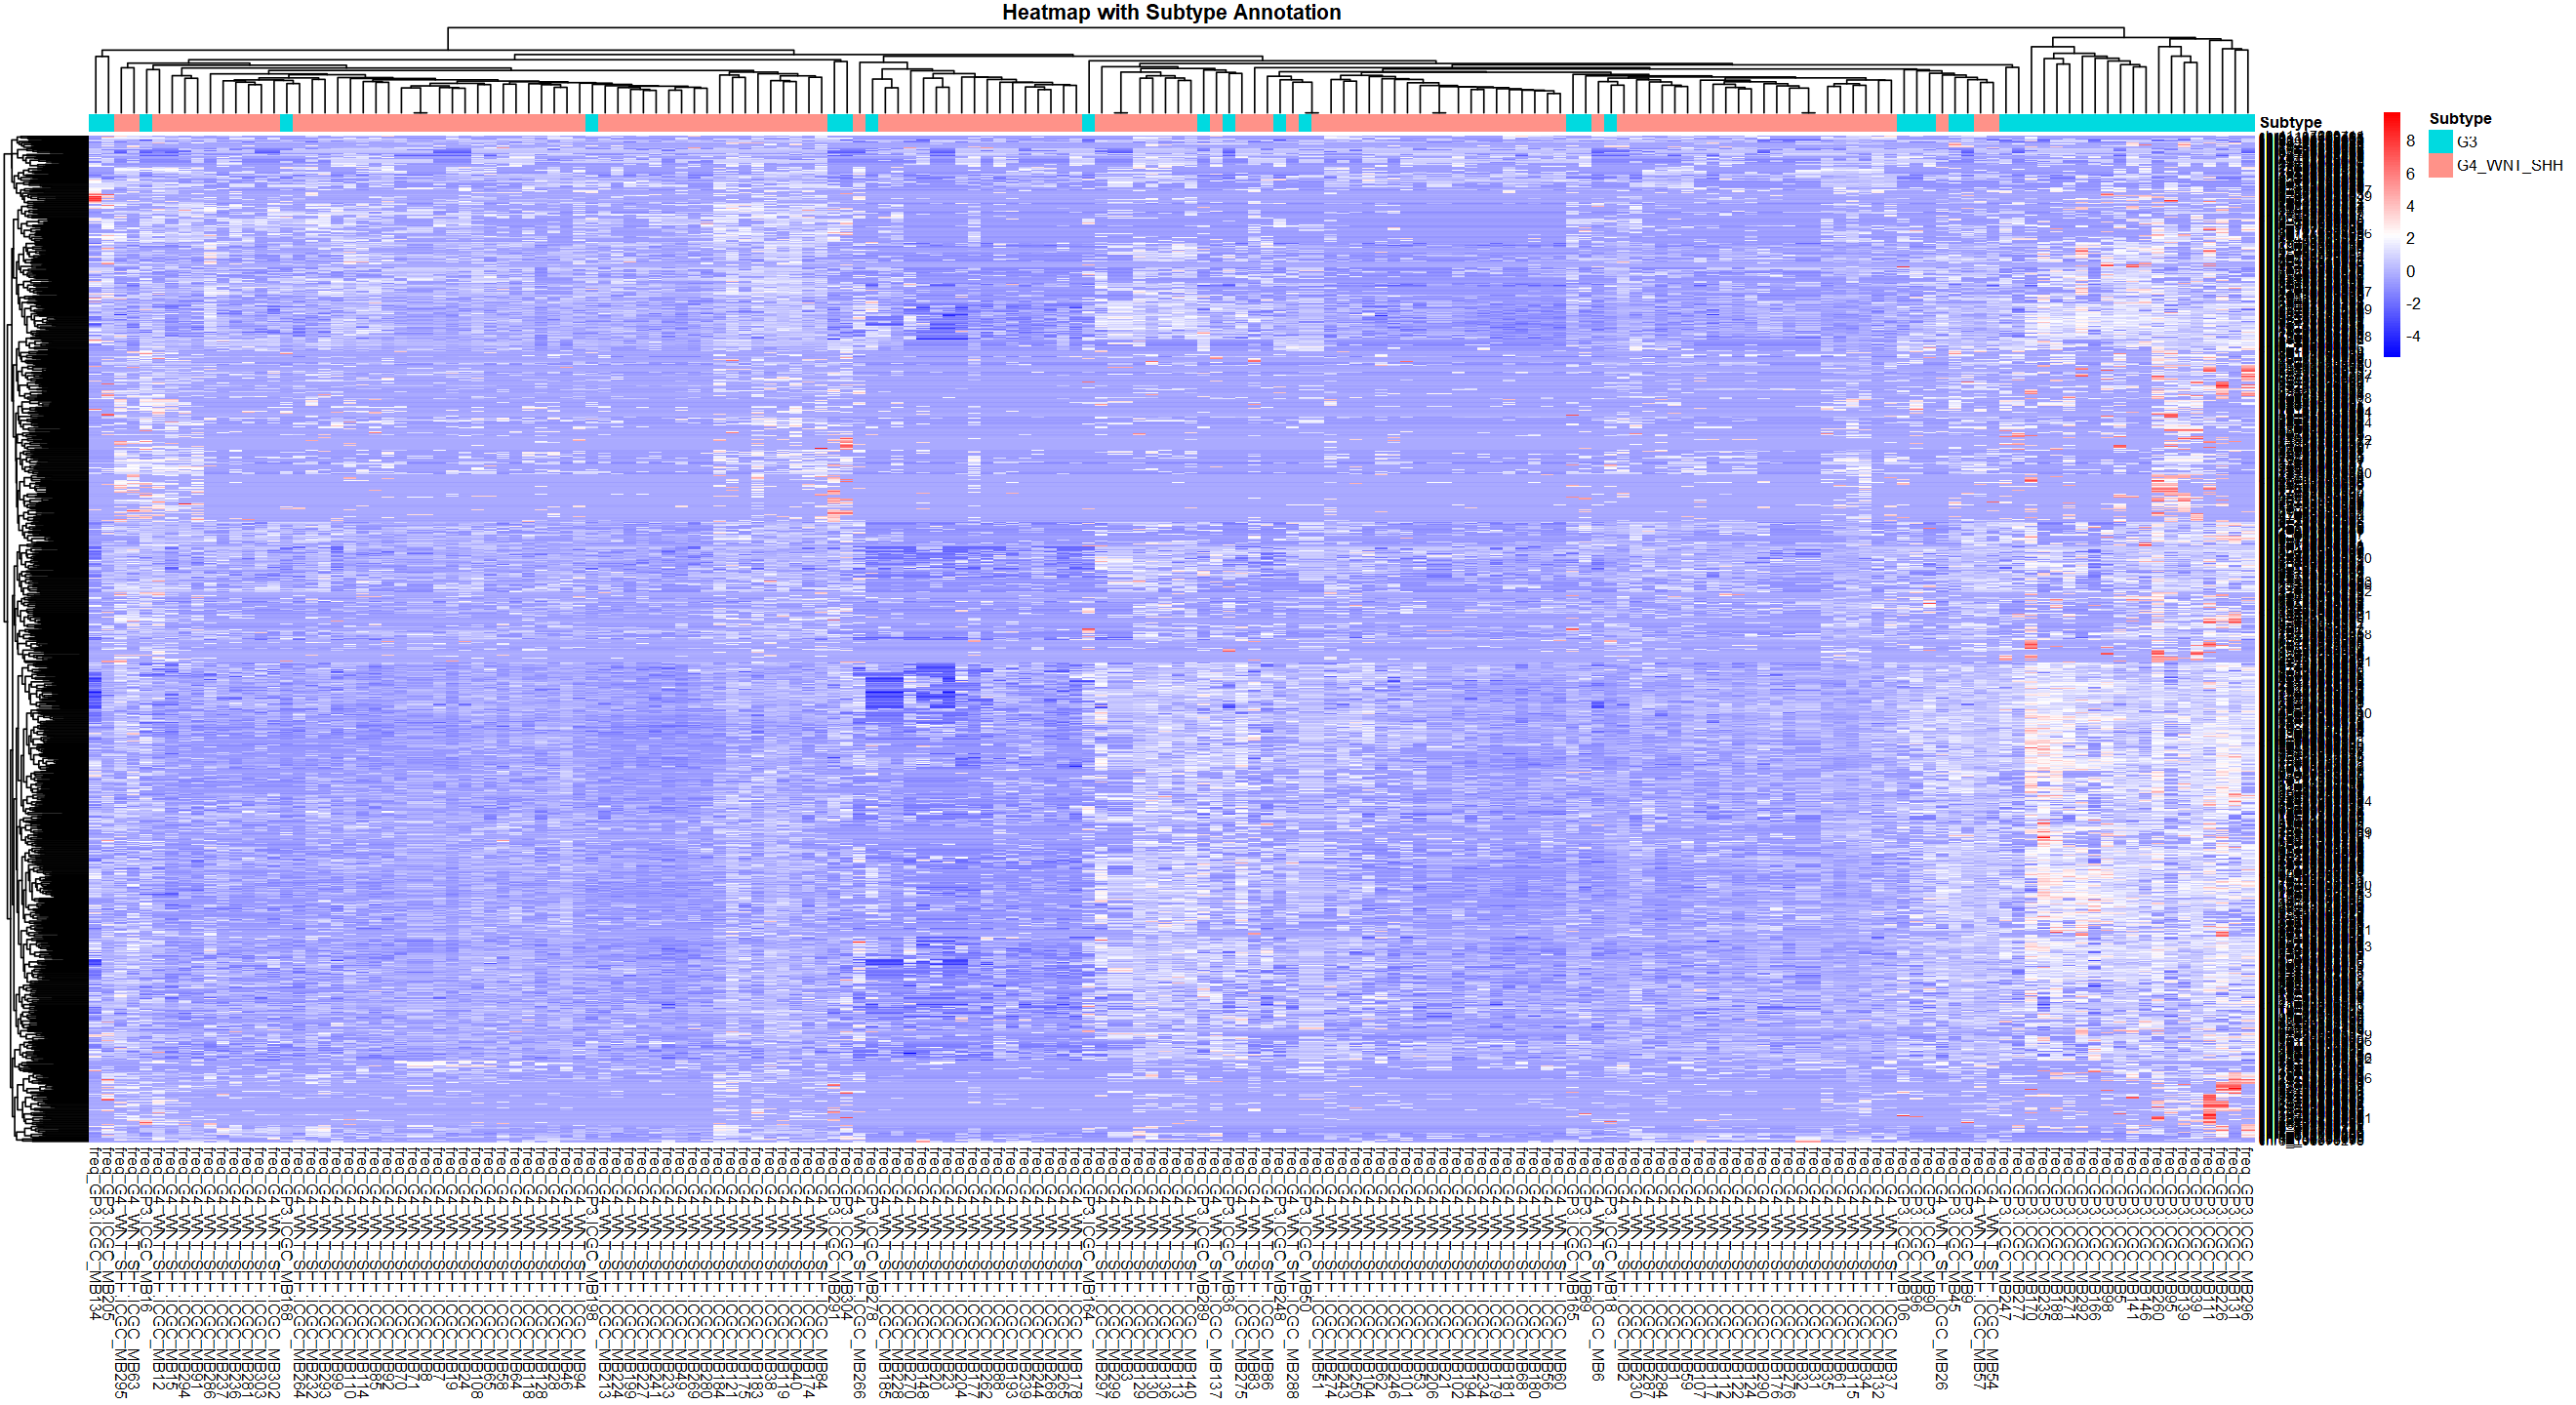

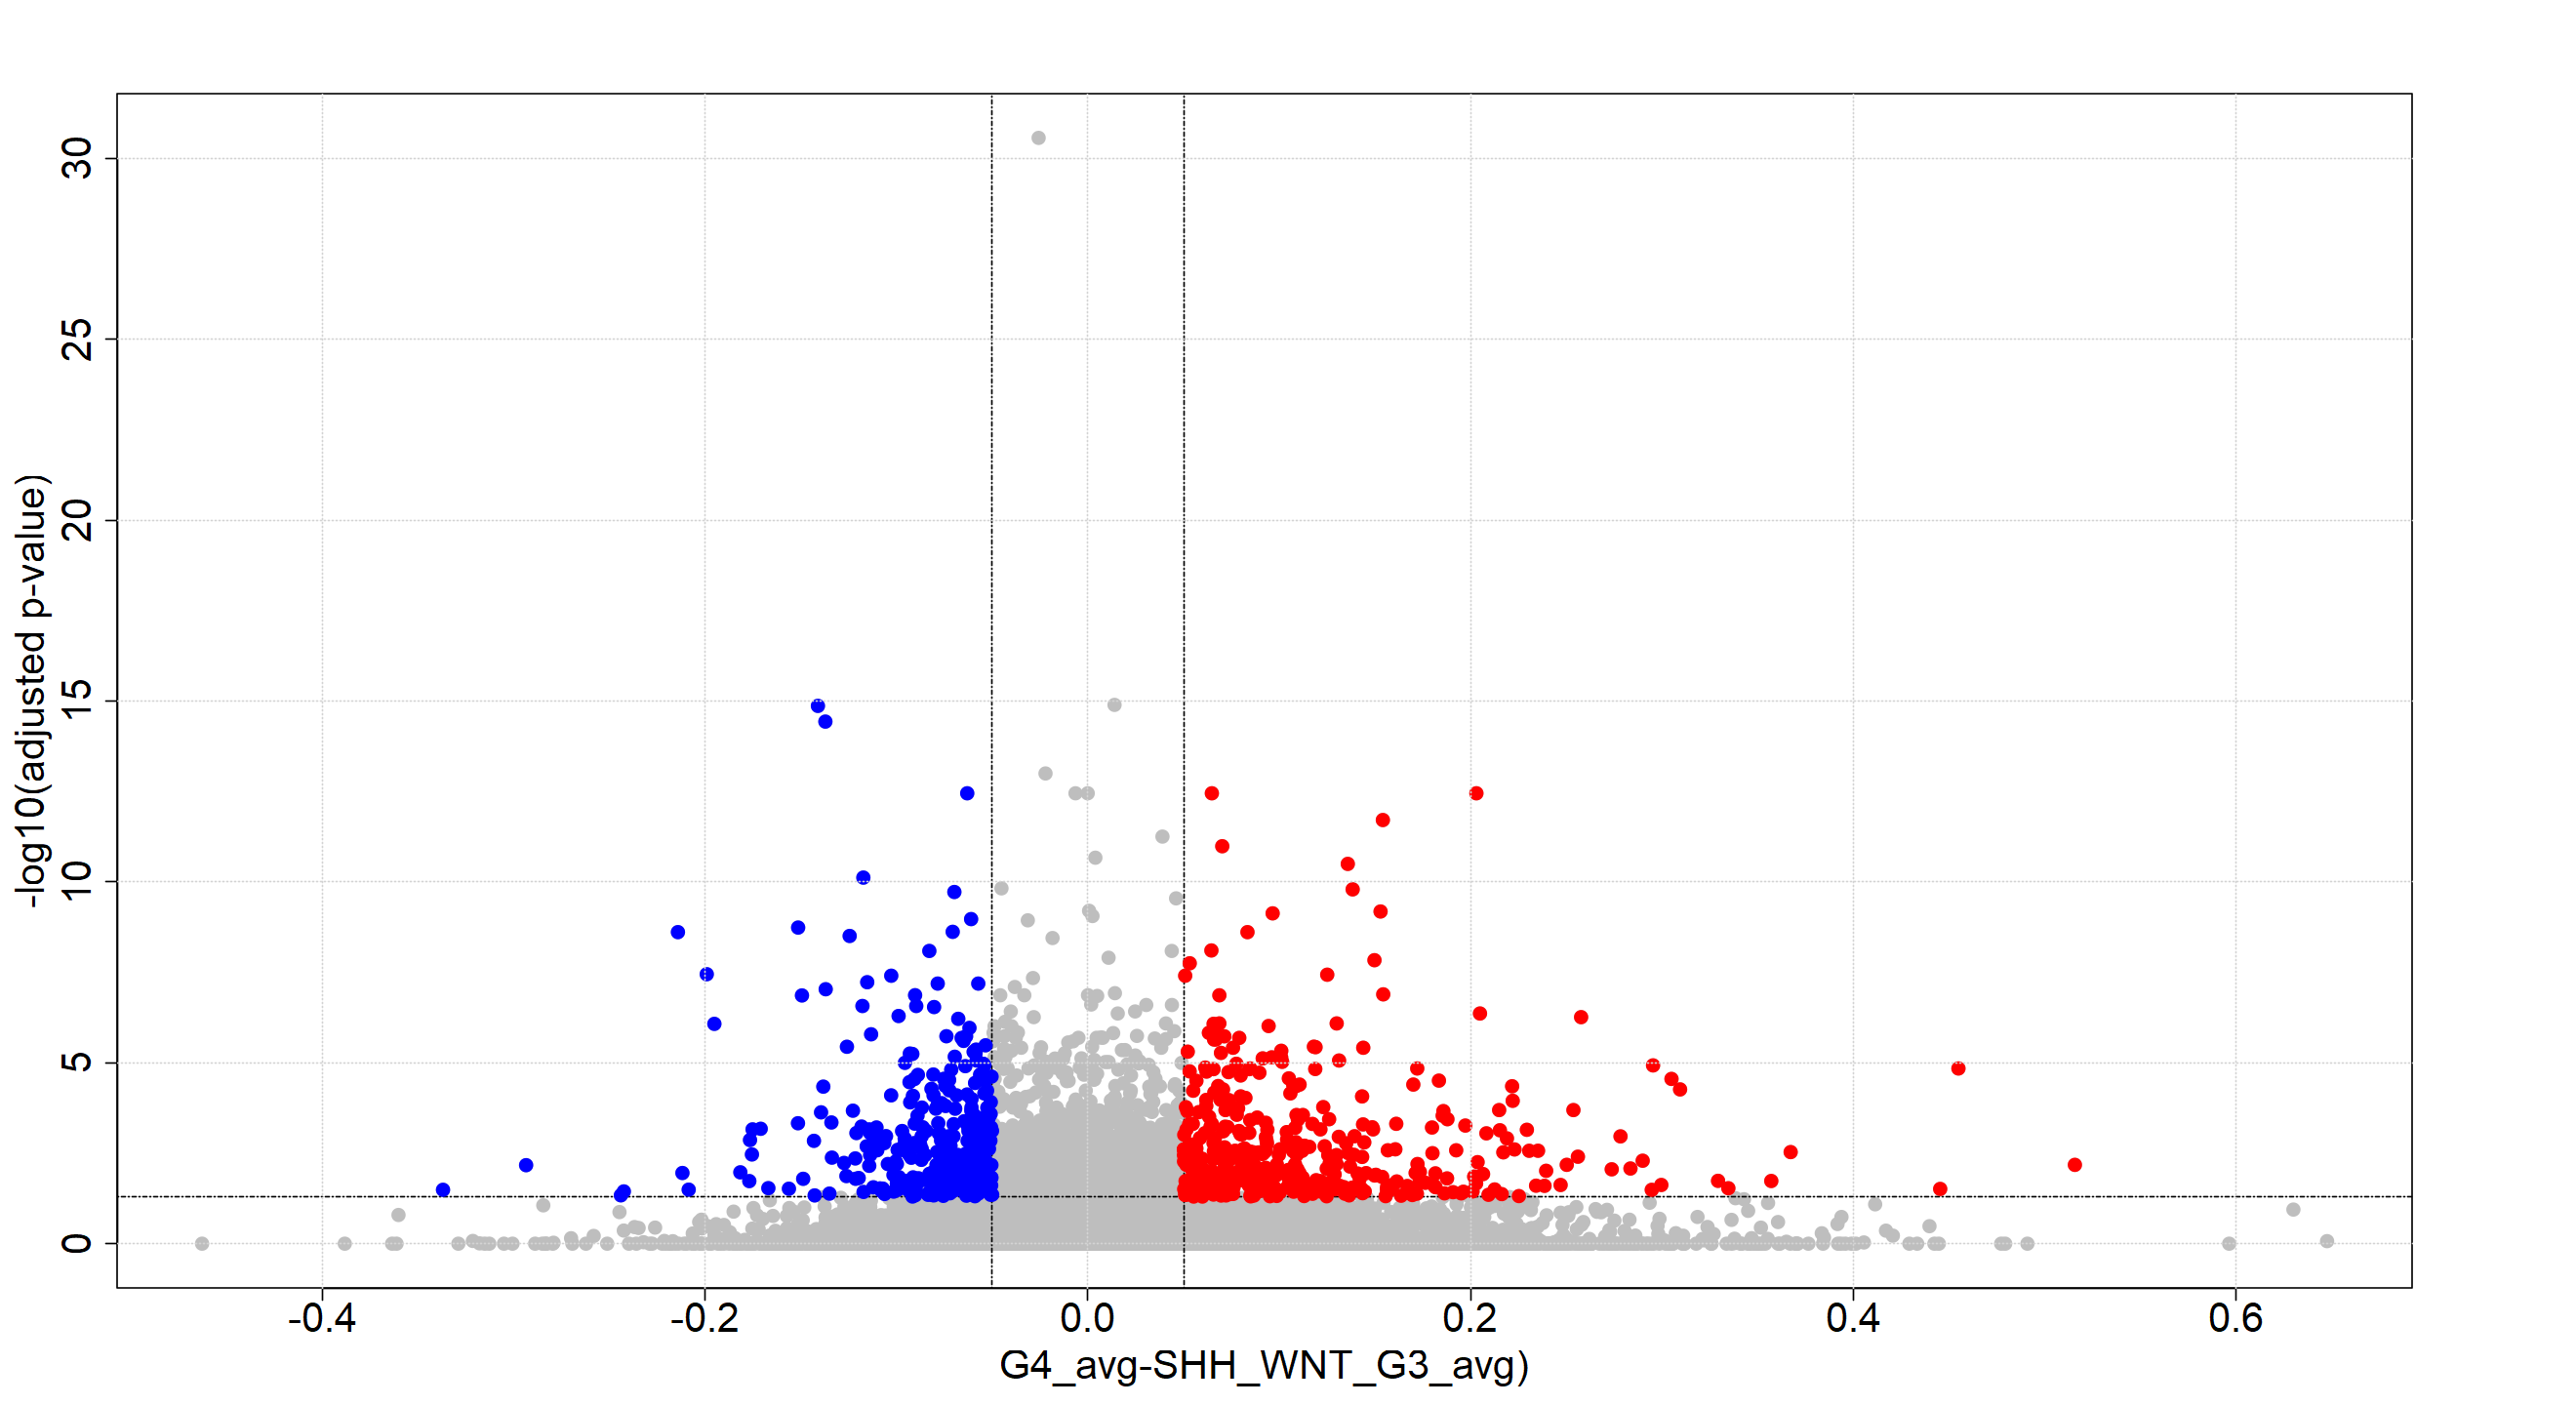

[1] "Number of sites with FDR P-value < 0.05"
[1] 2119


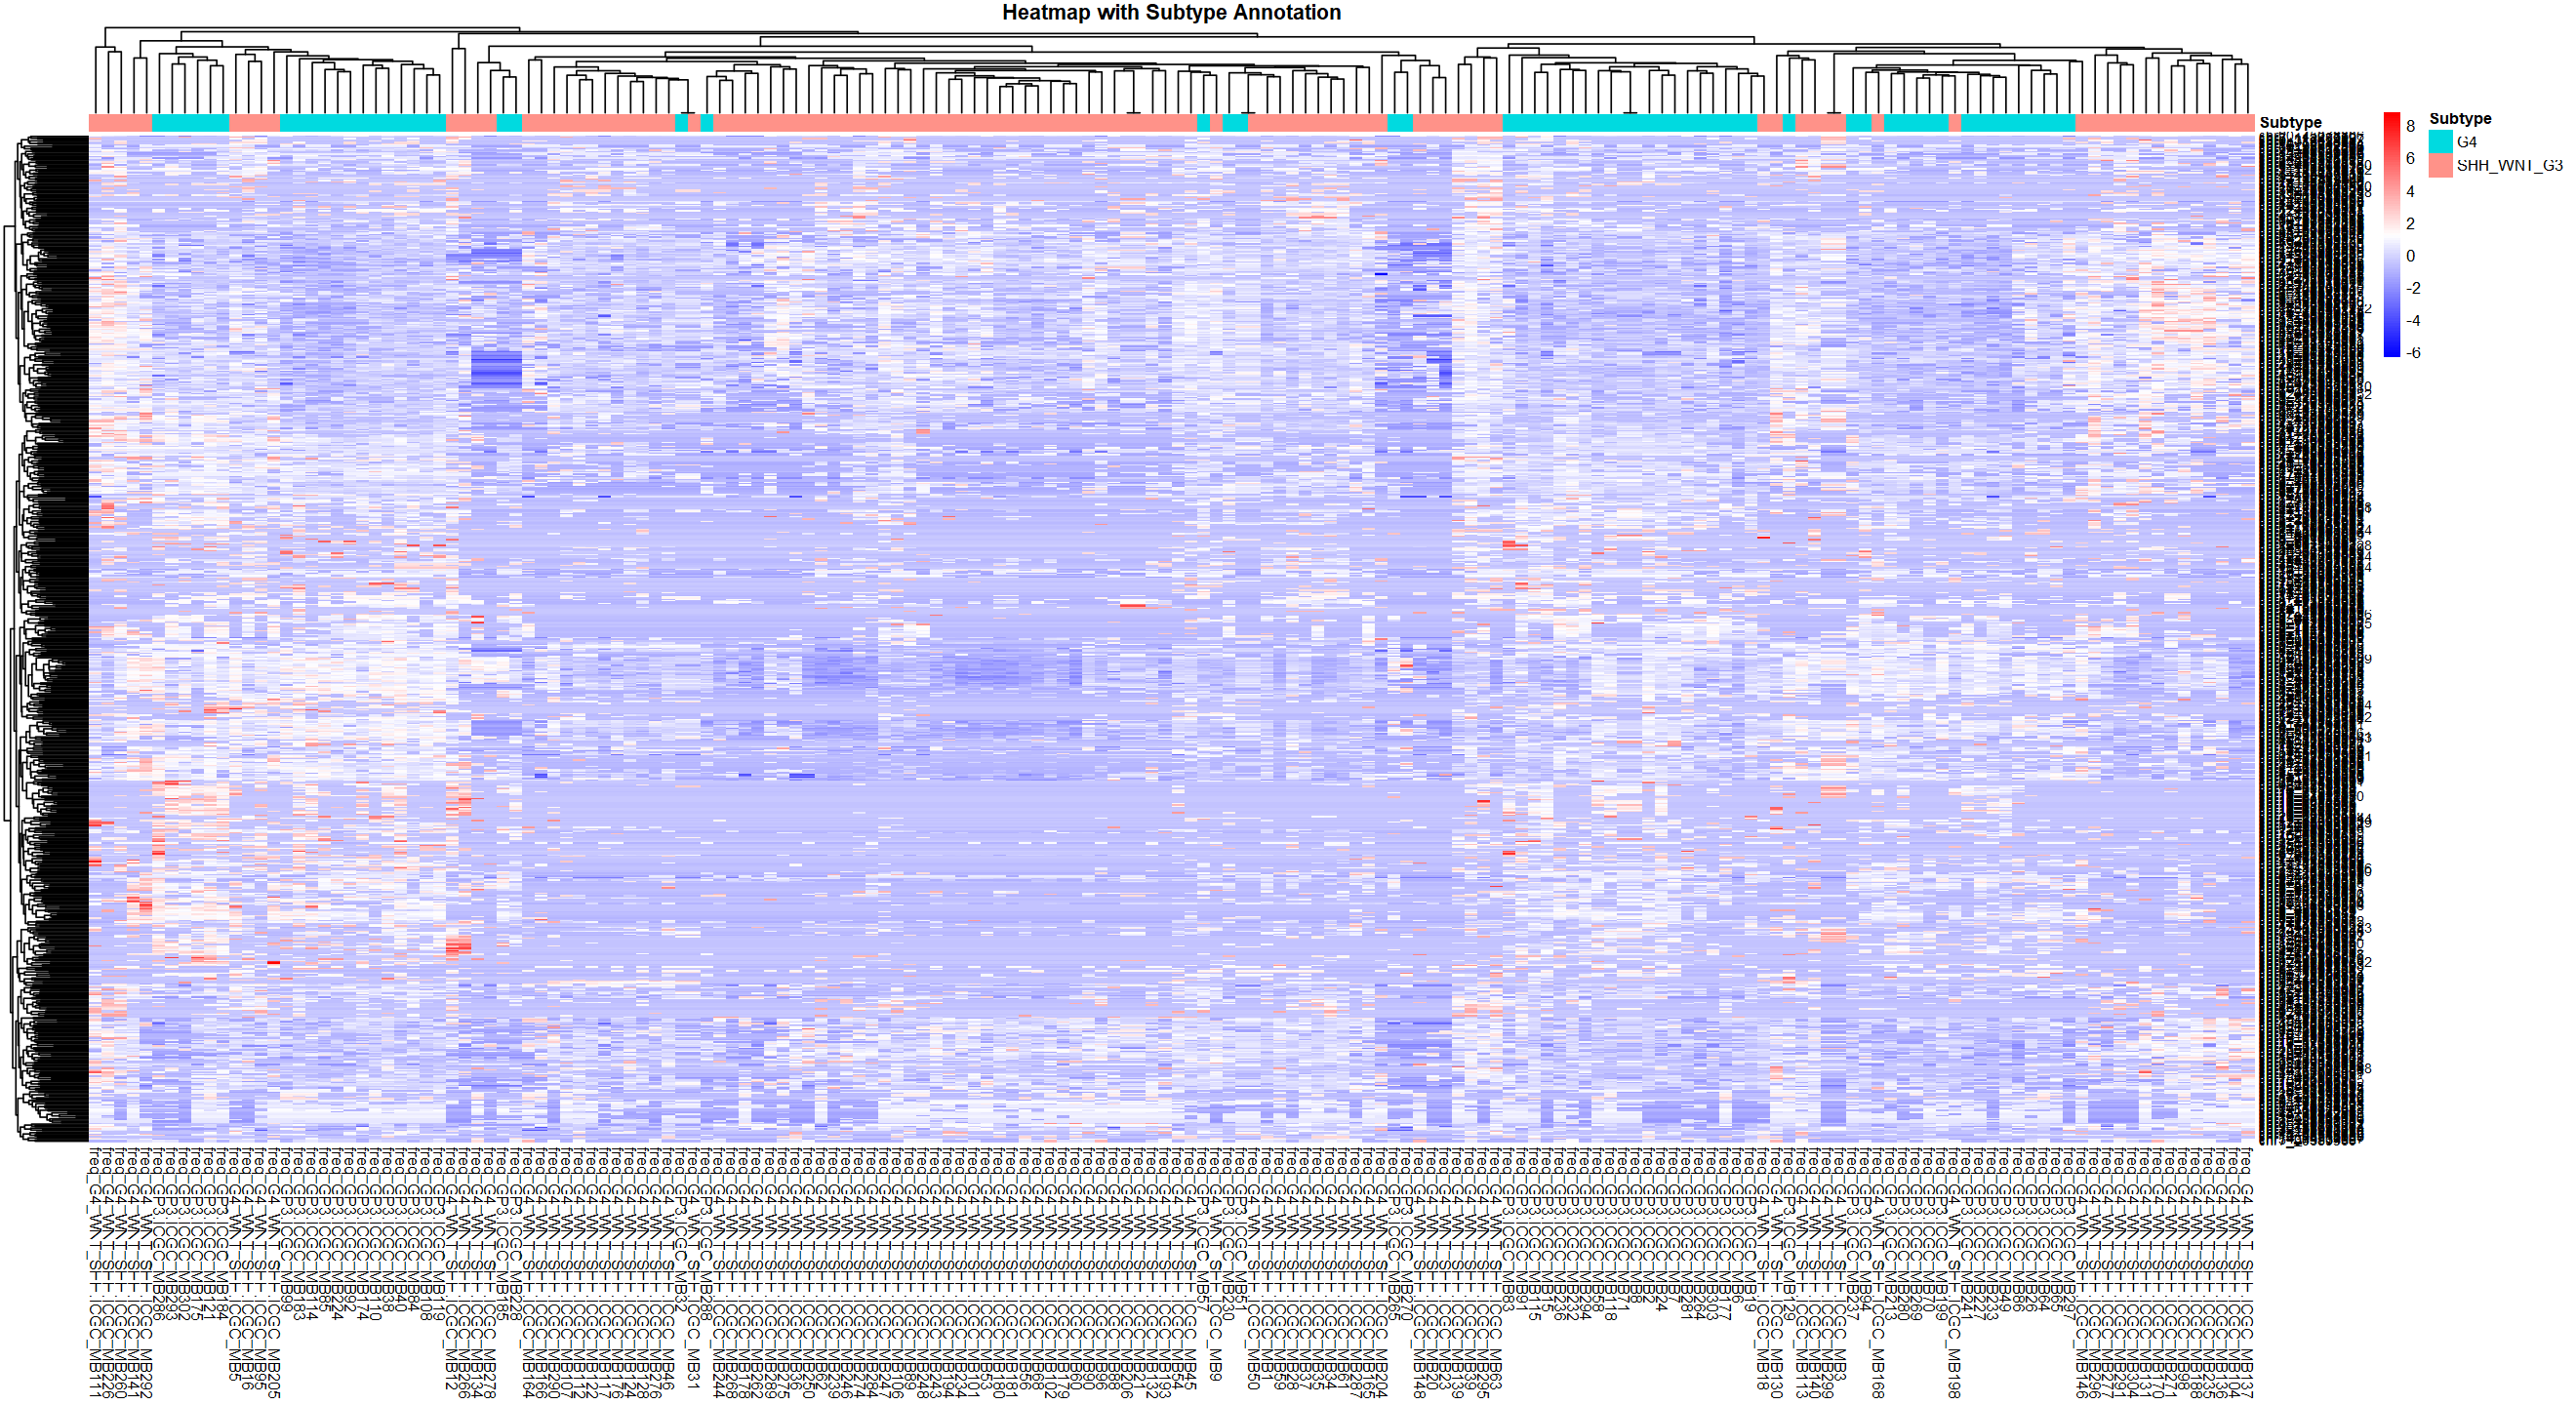

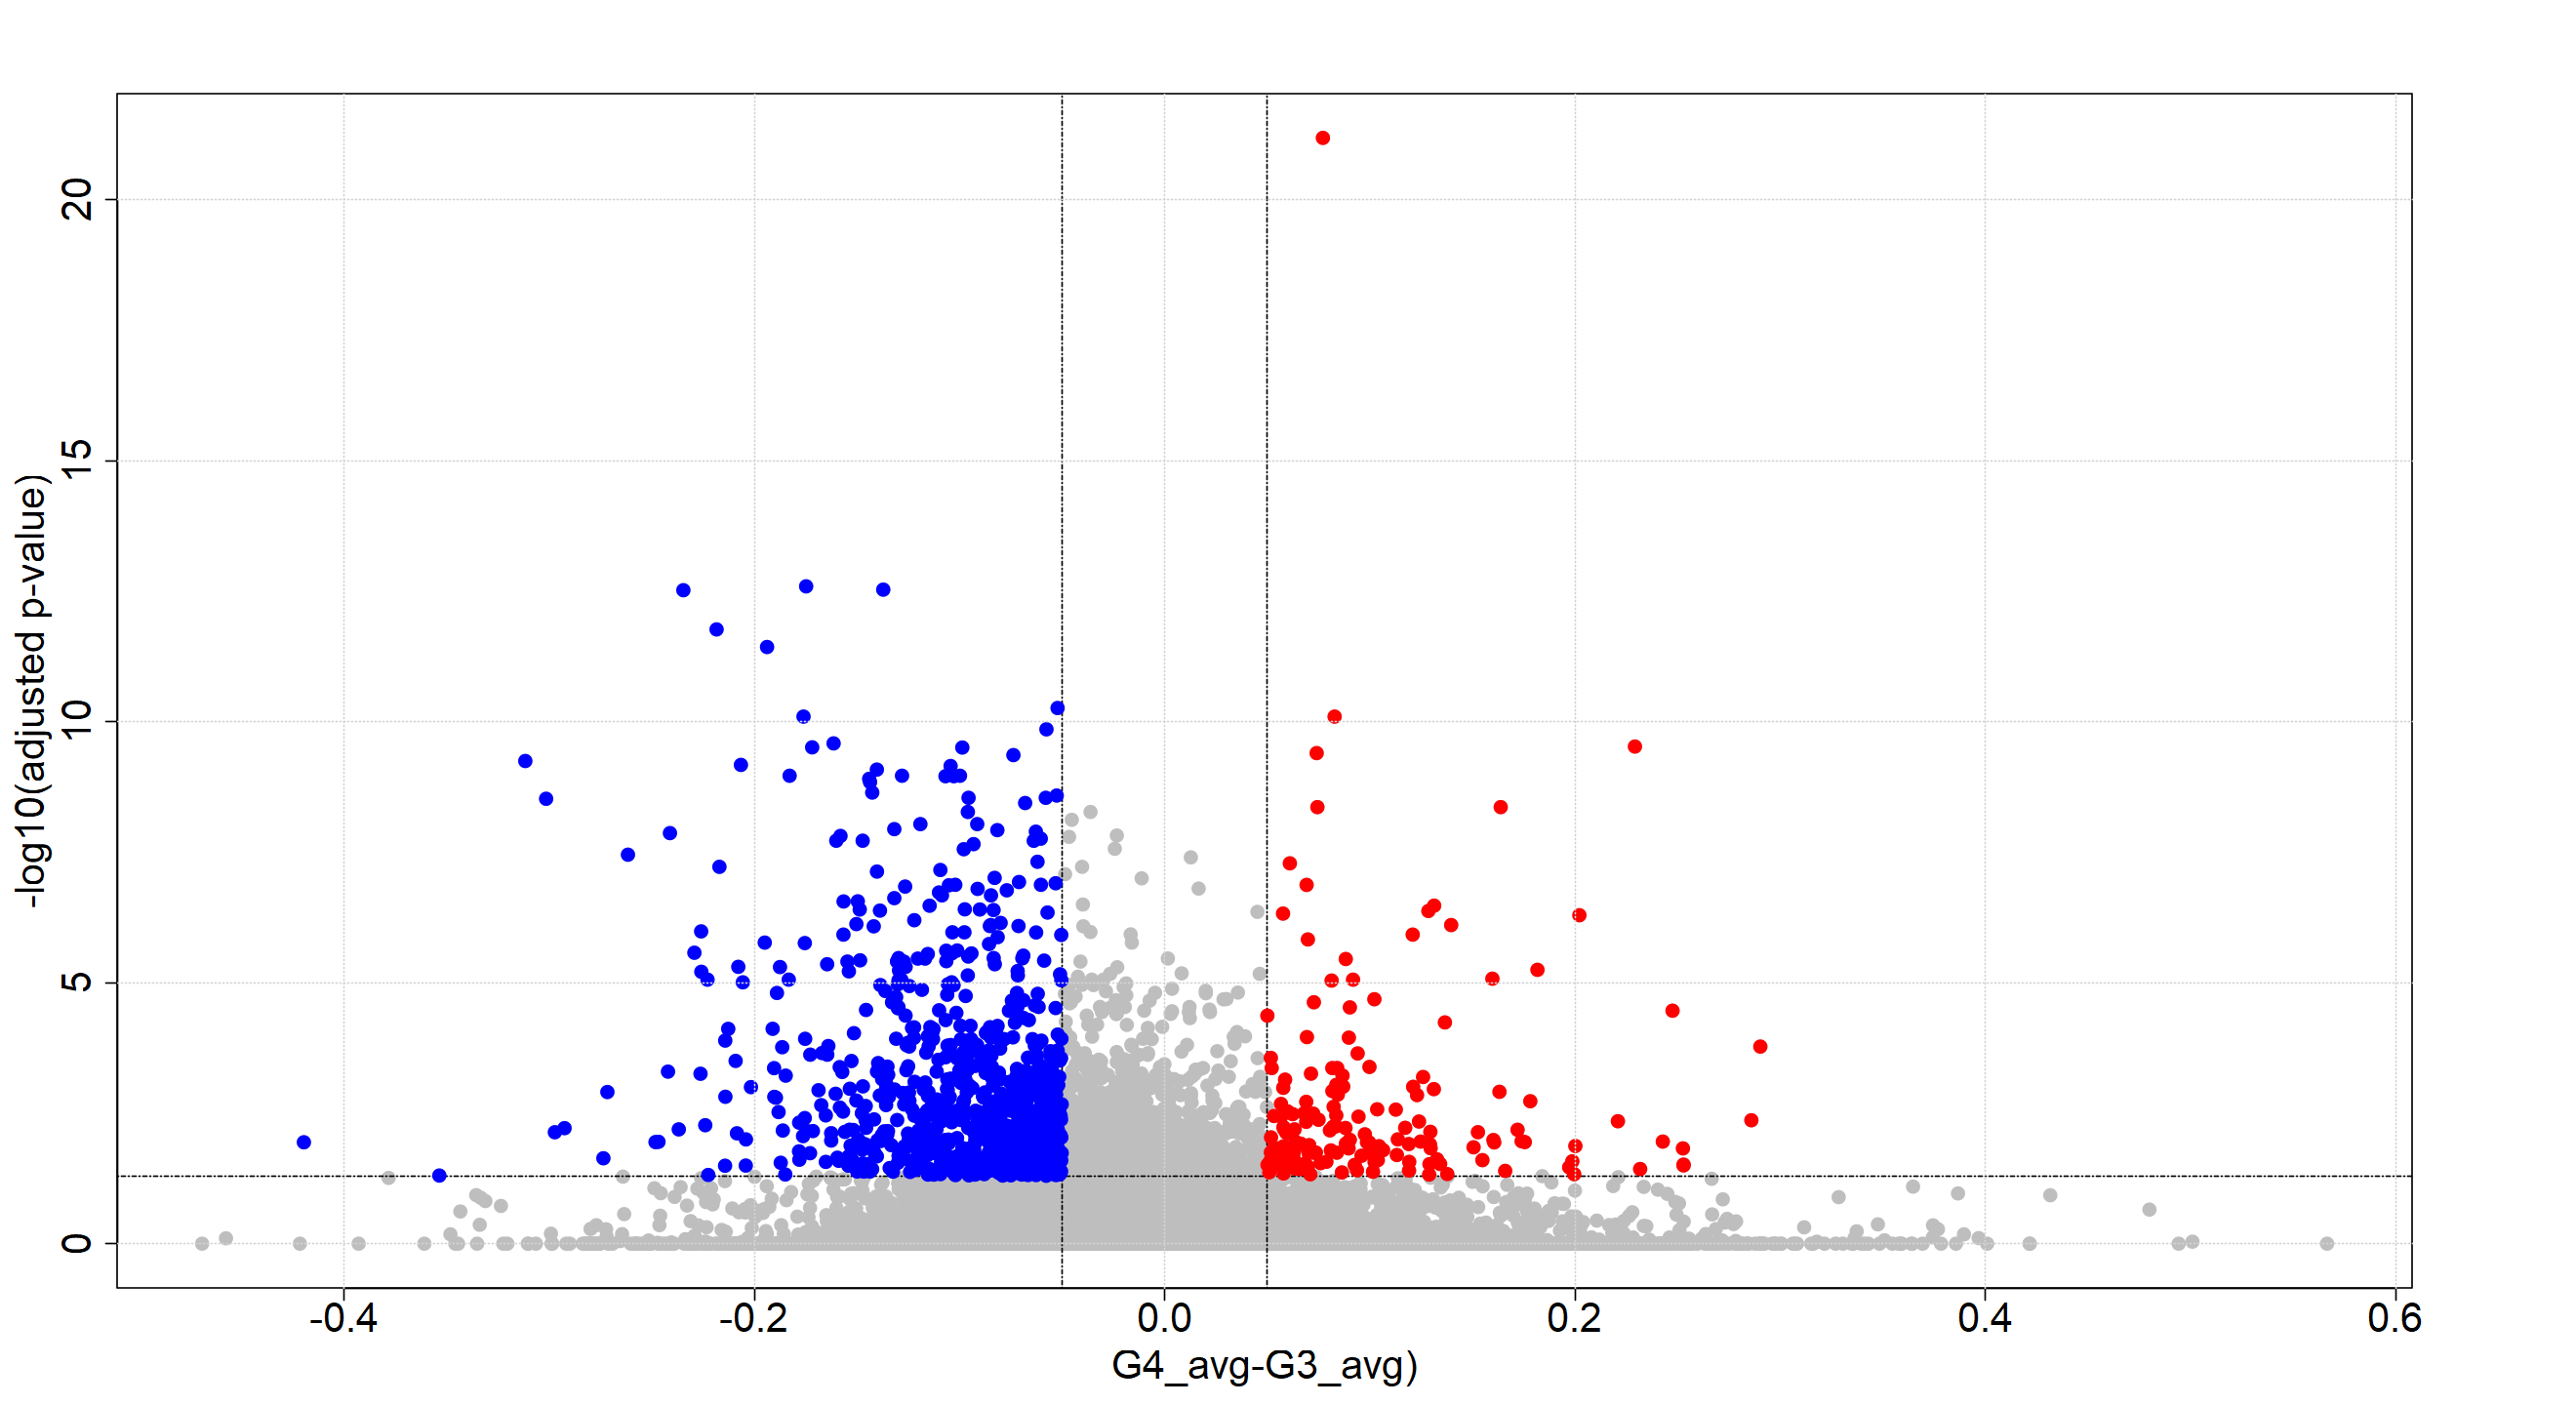

[1] "Number of sites with FDR P-value < 0.05"
[1] 1662


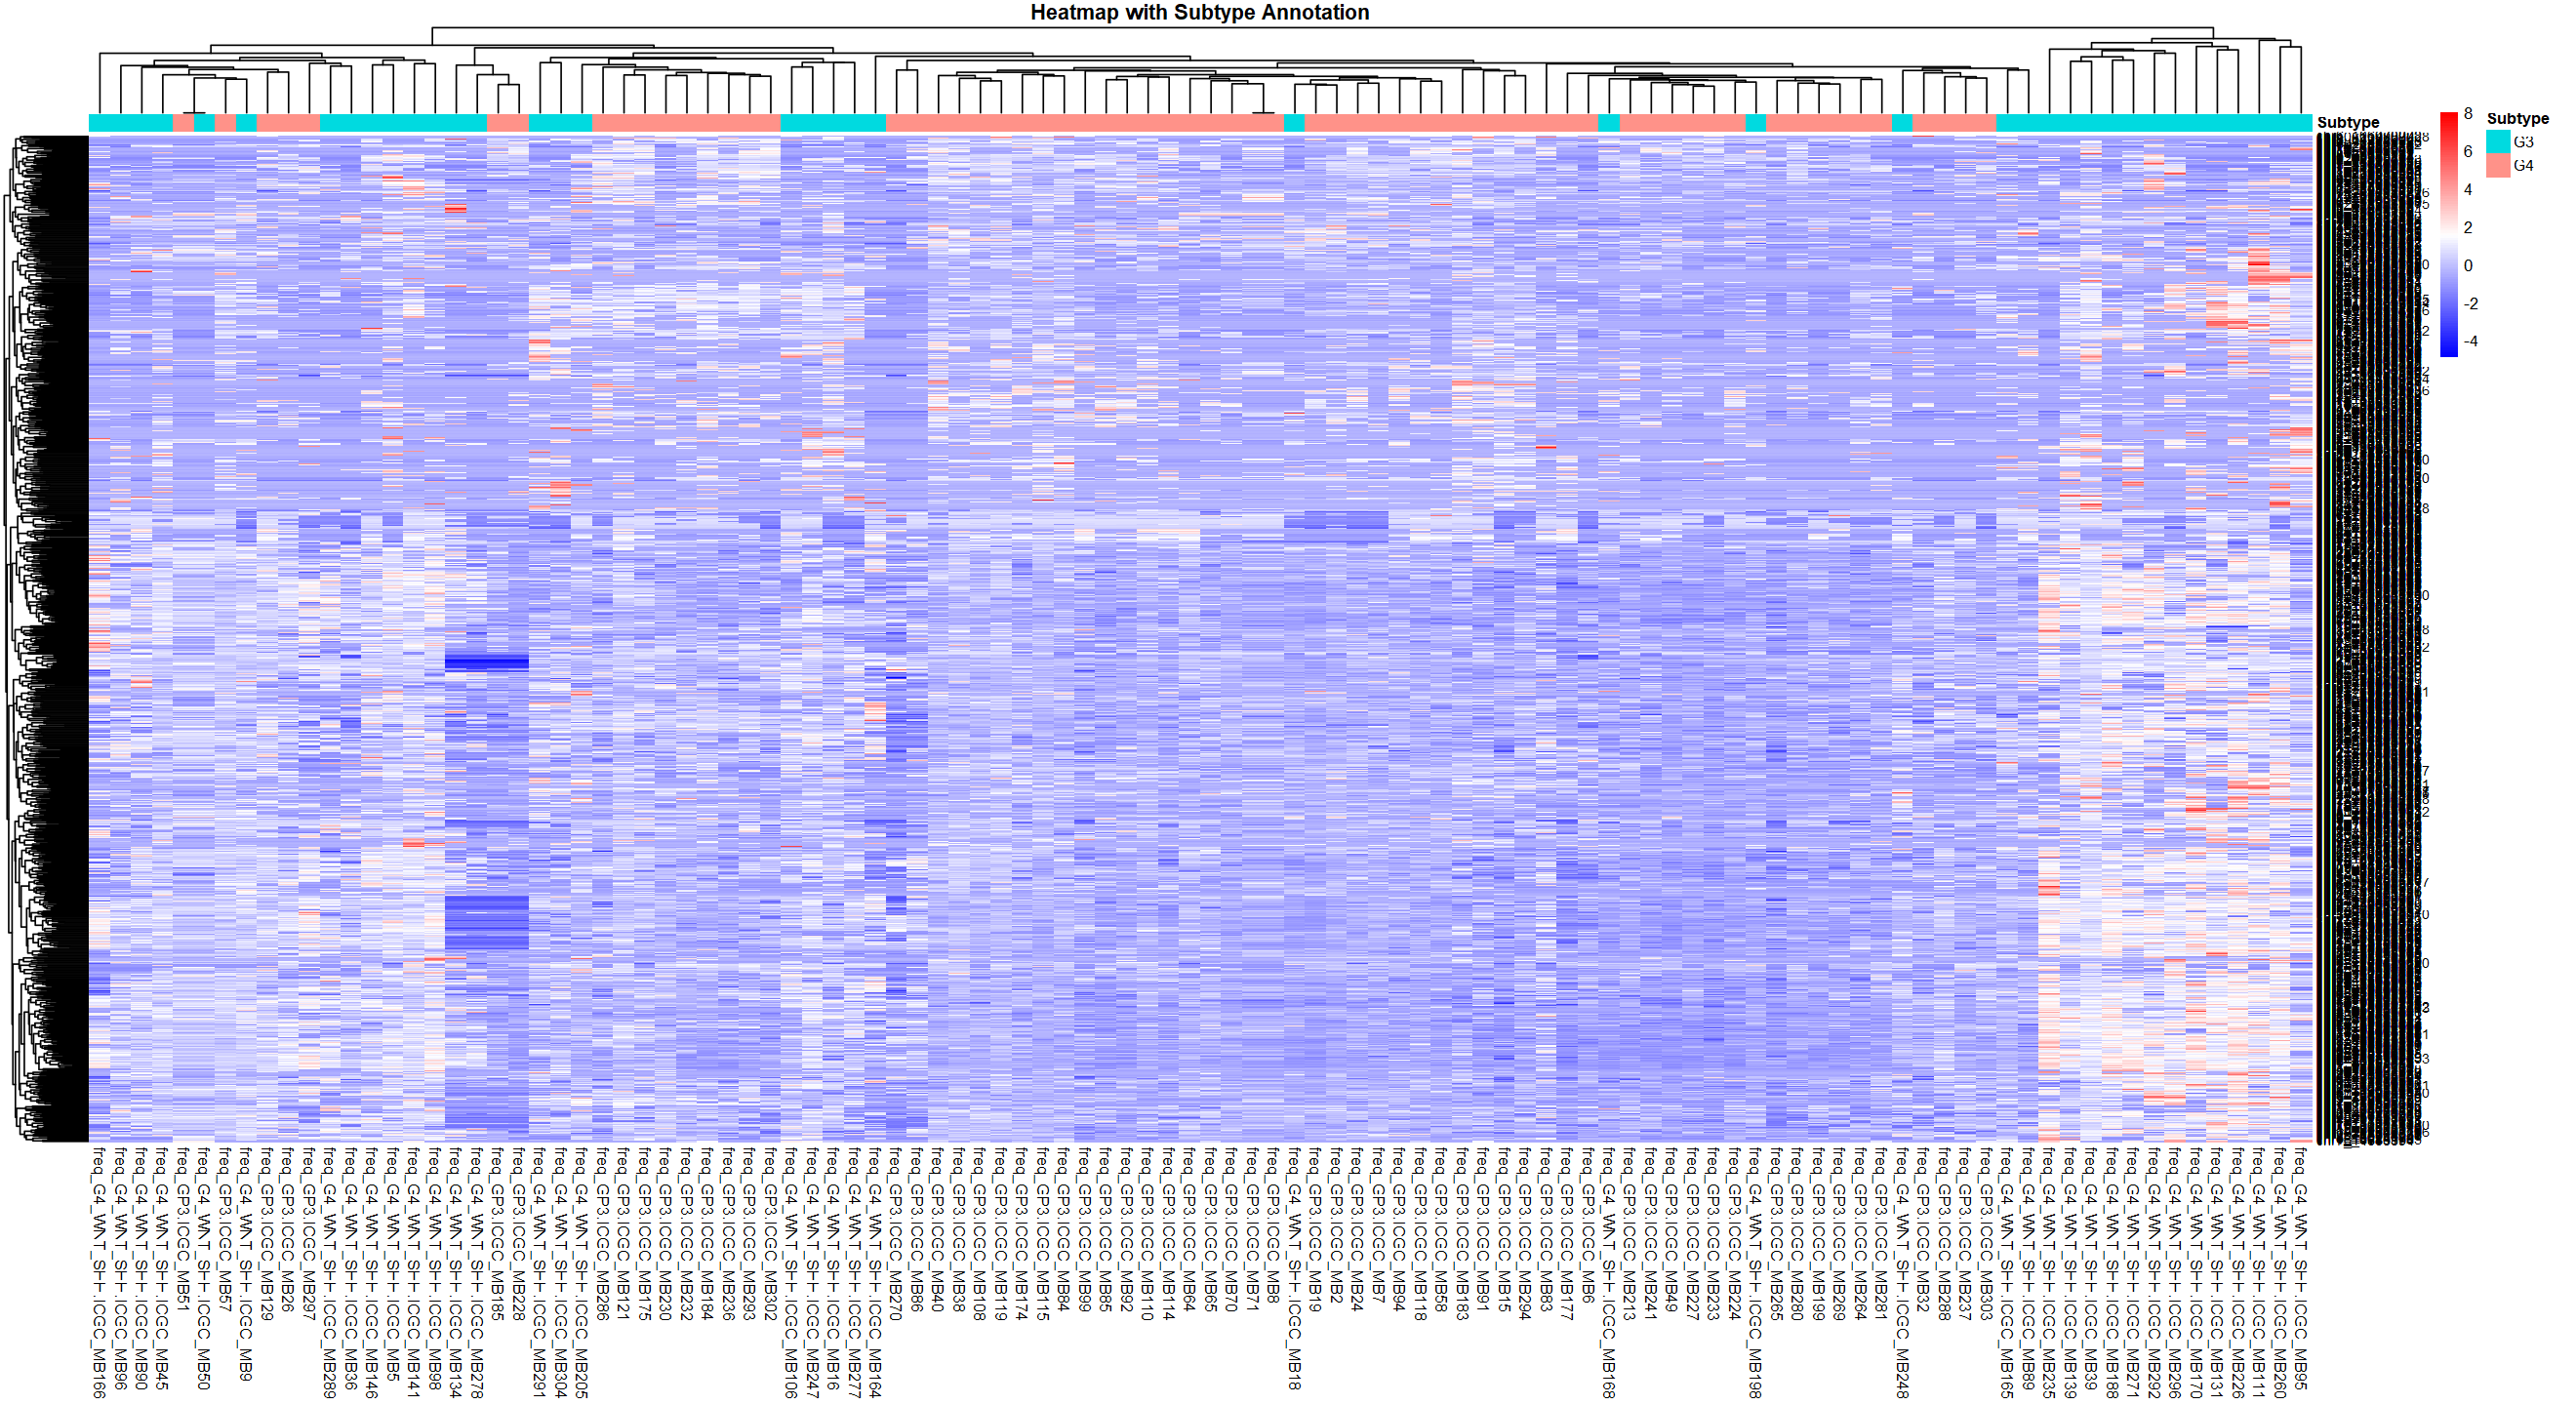

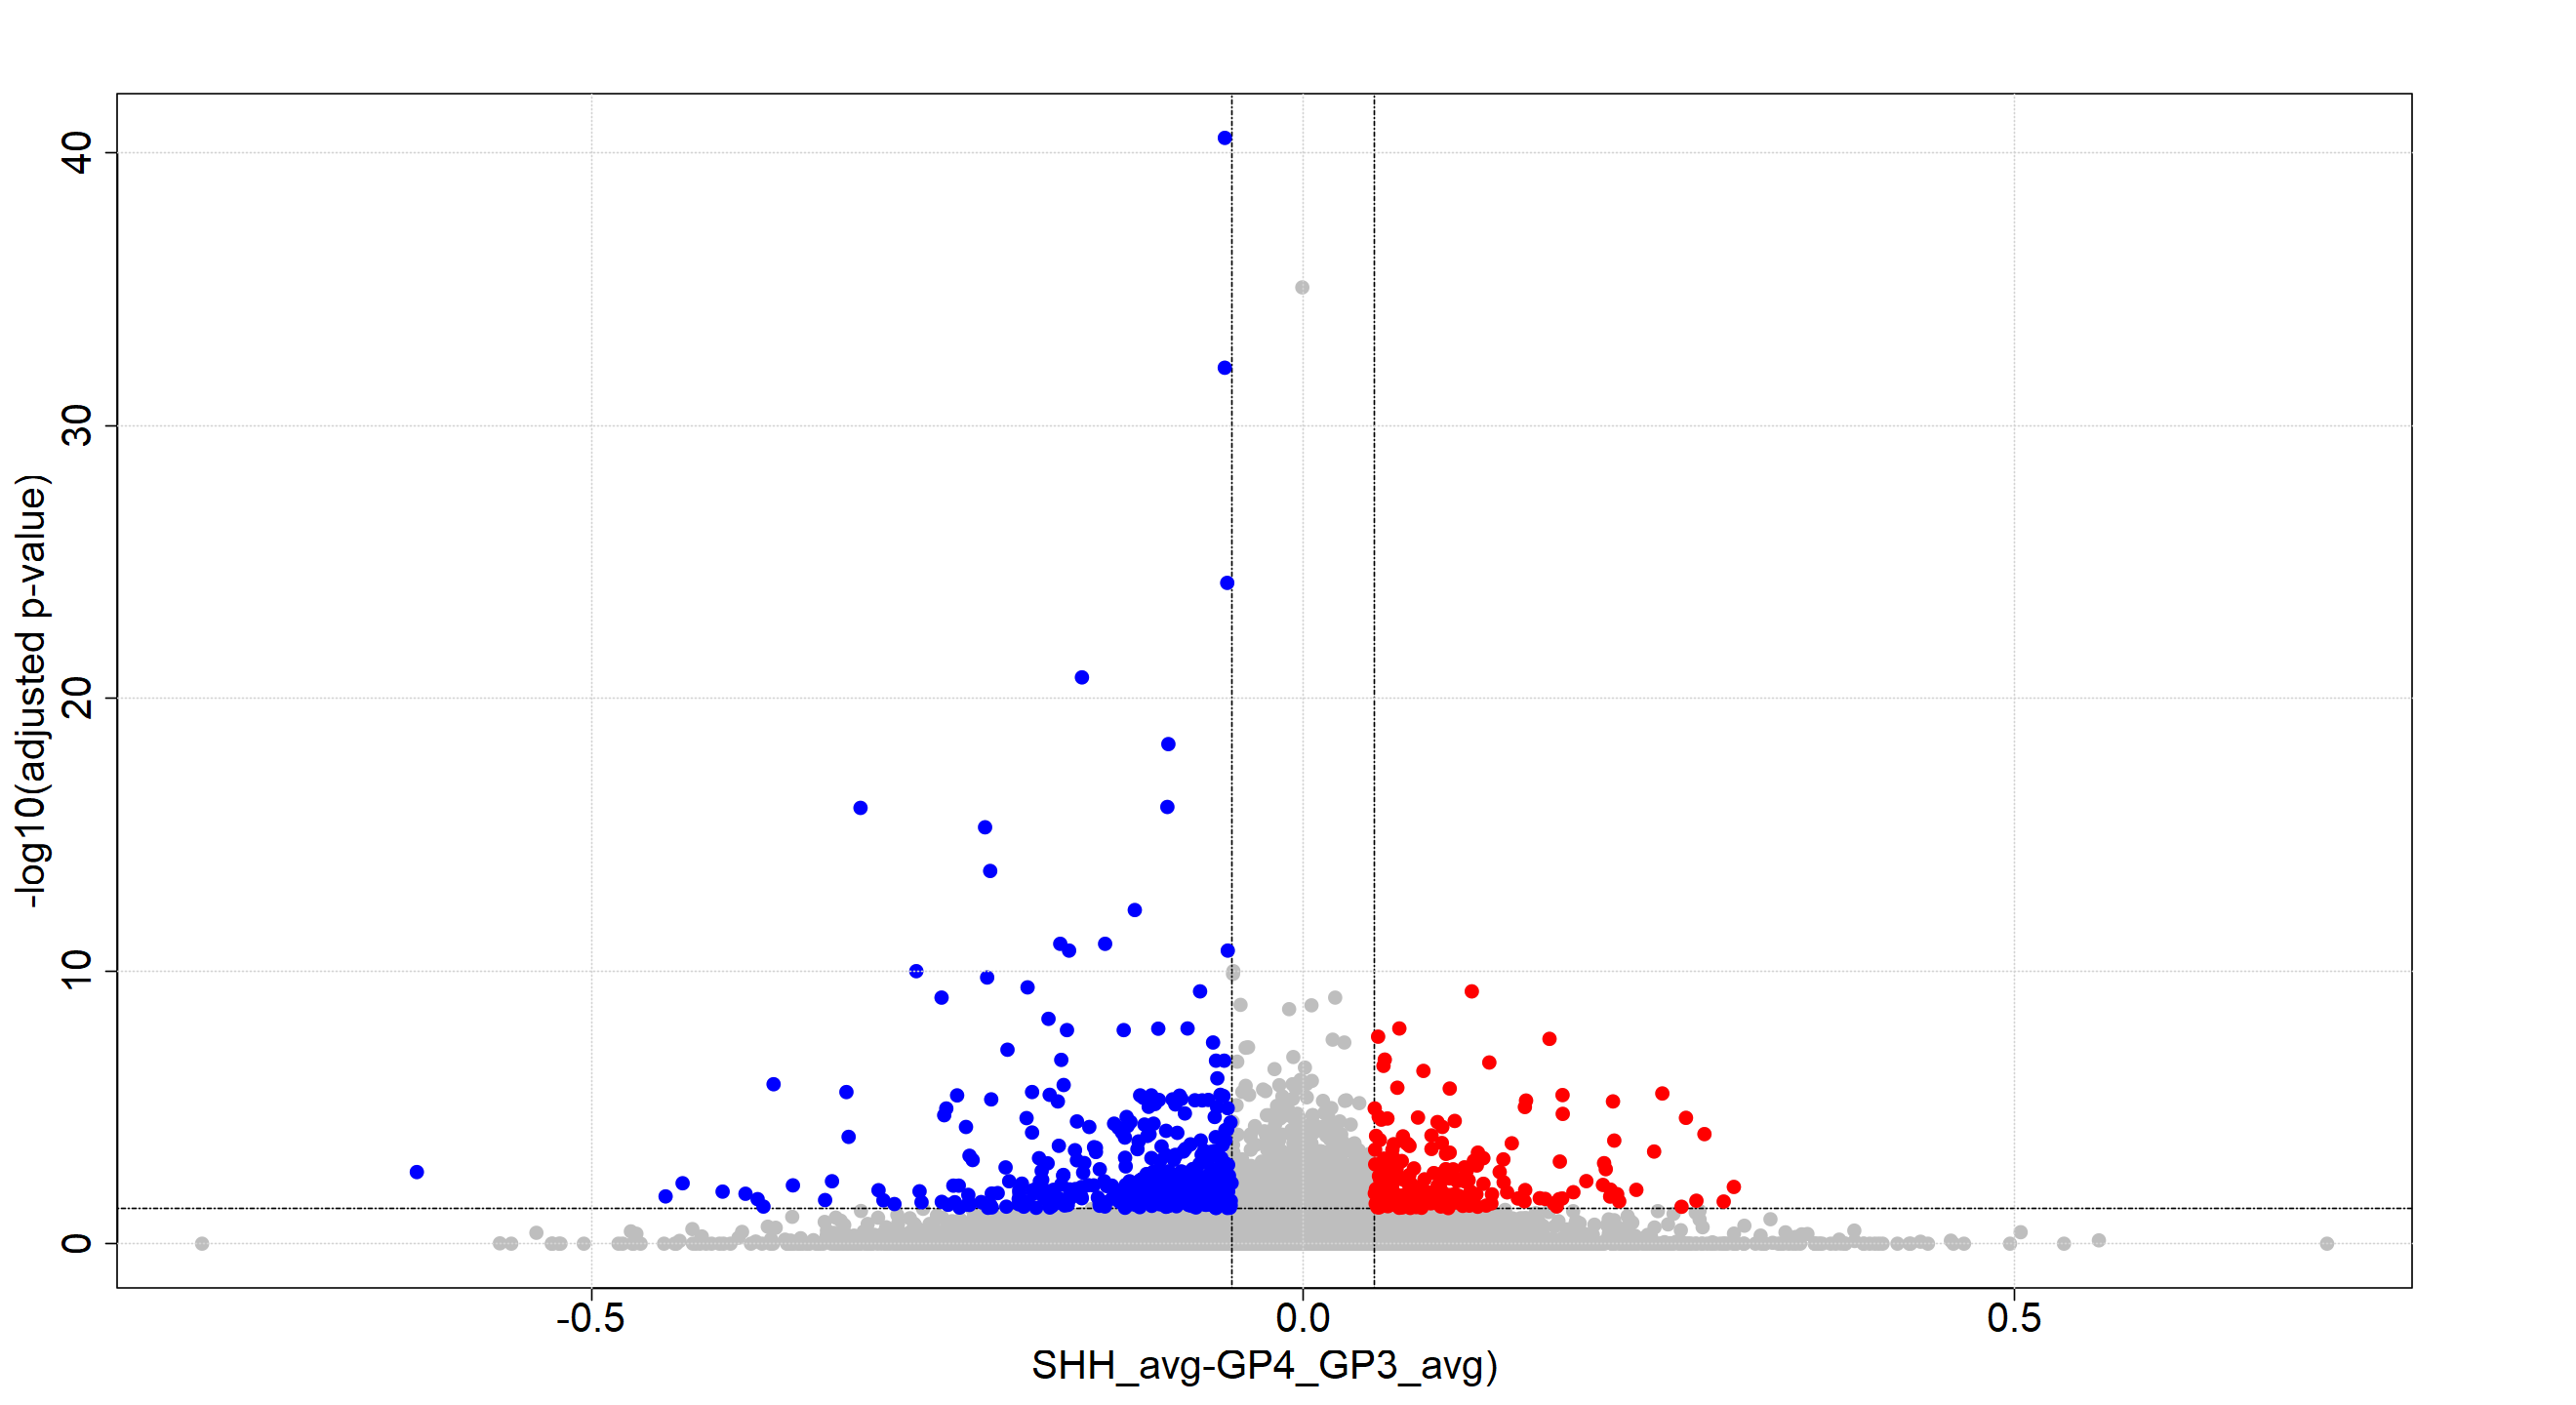

[1] "Number of sites with FDR P-value < 0.05"
[1] 382


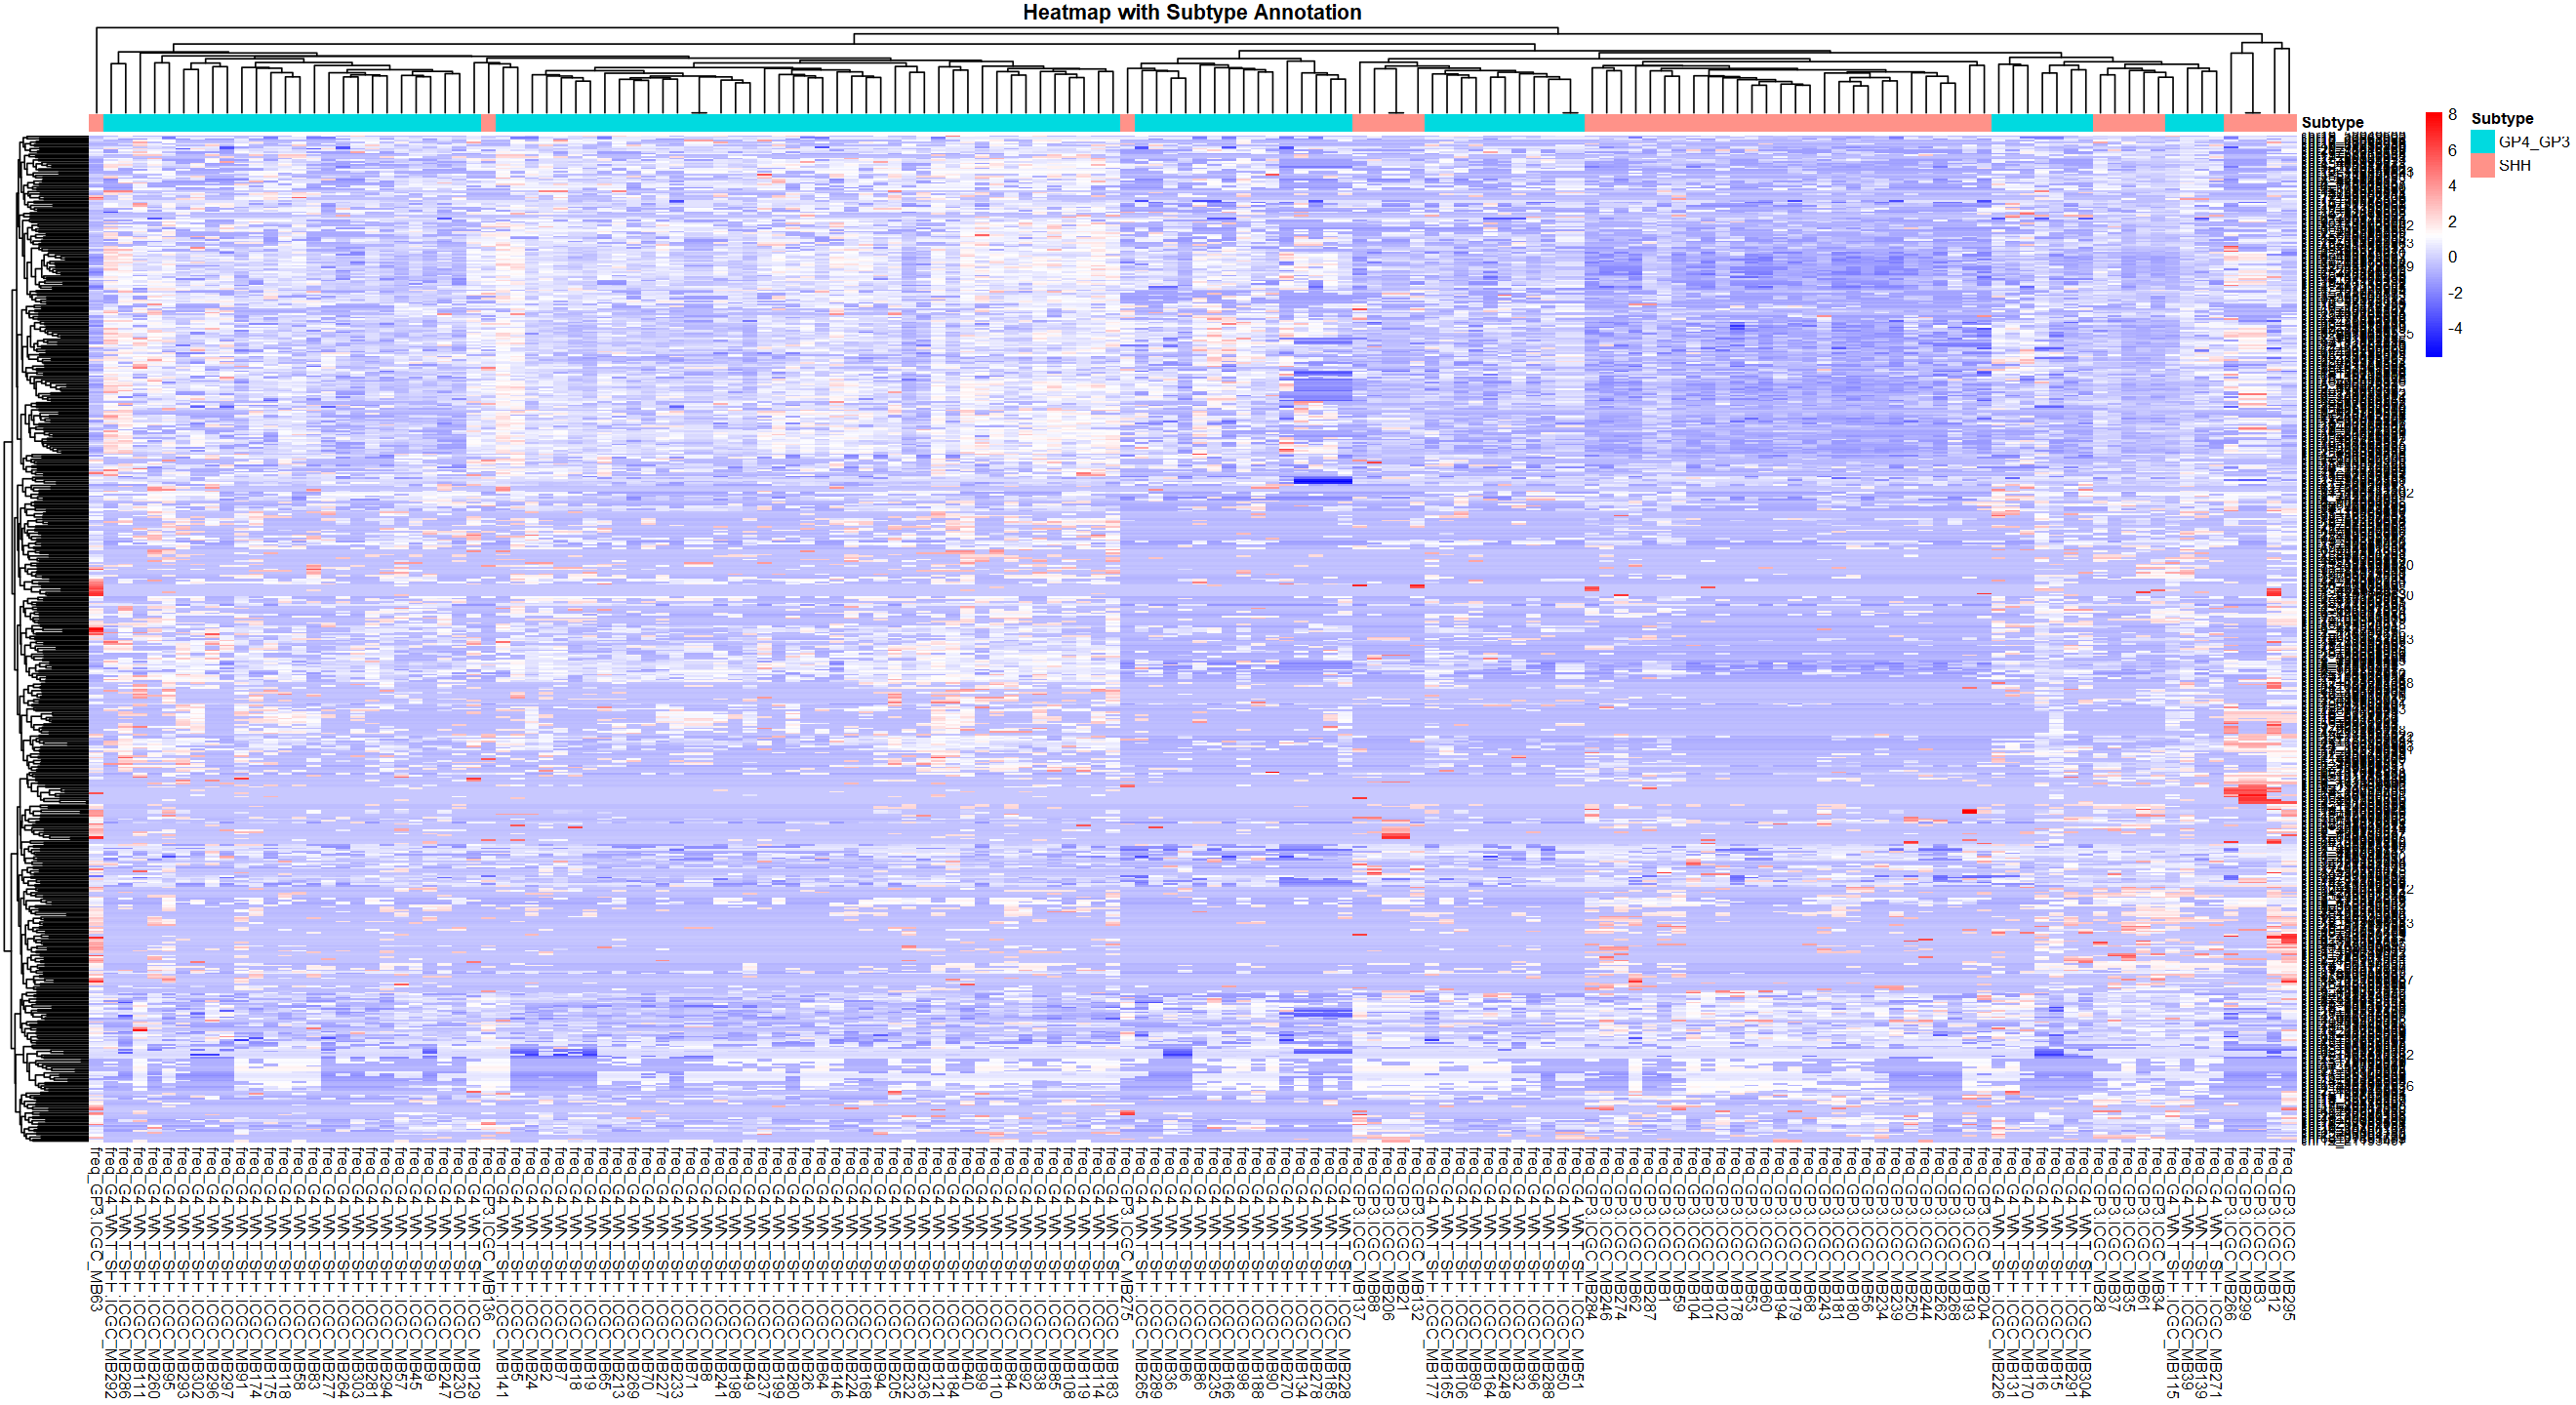

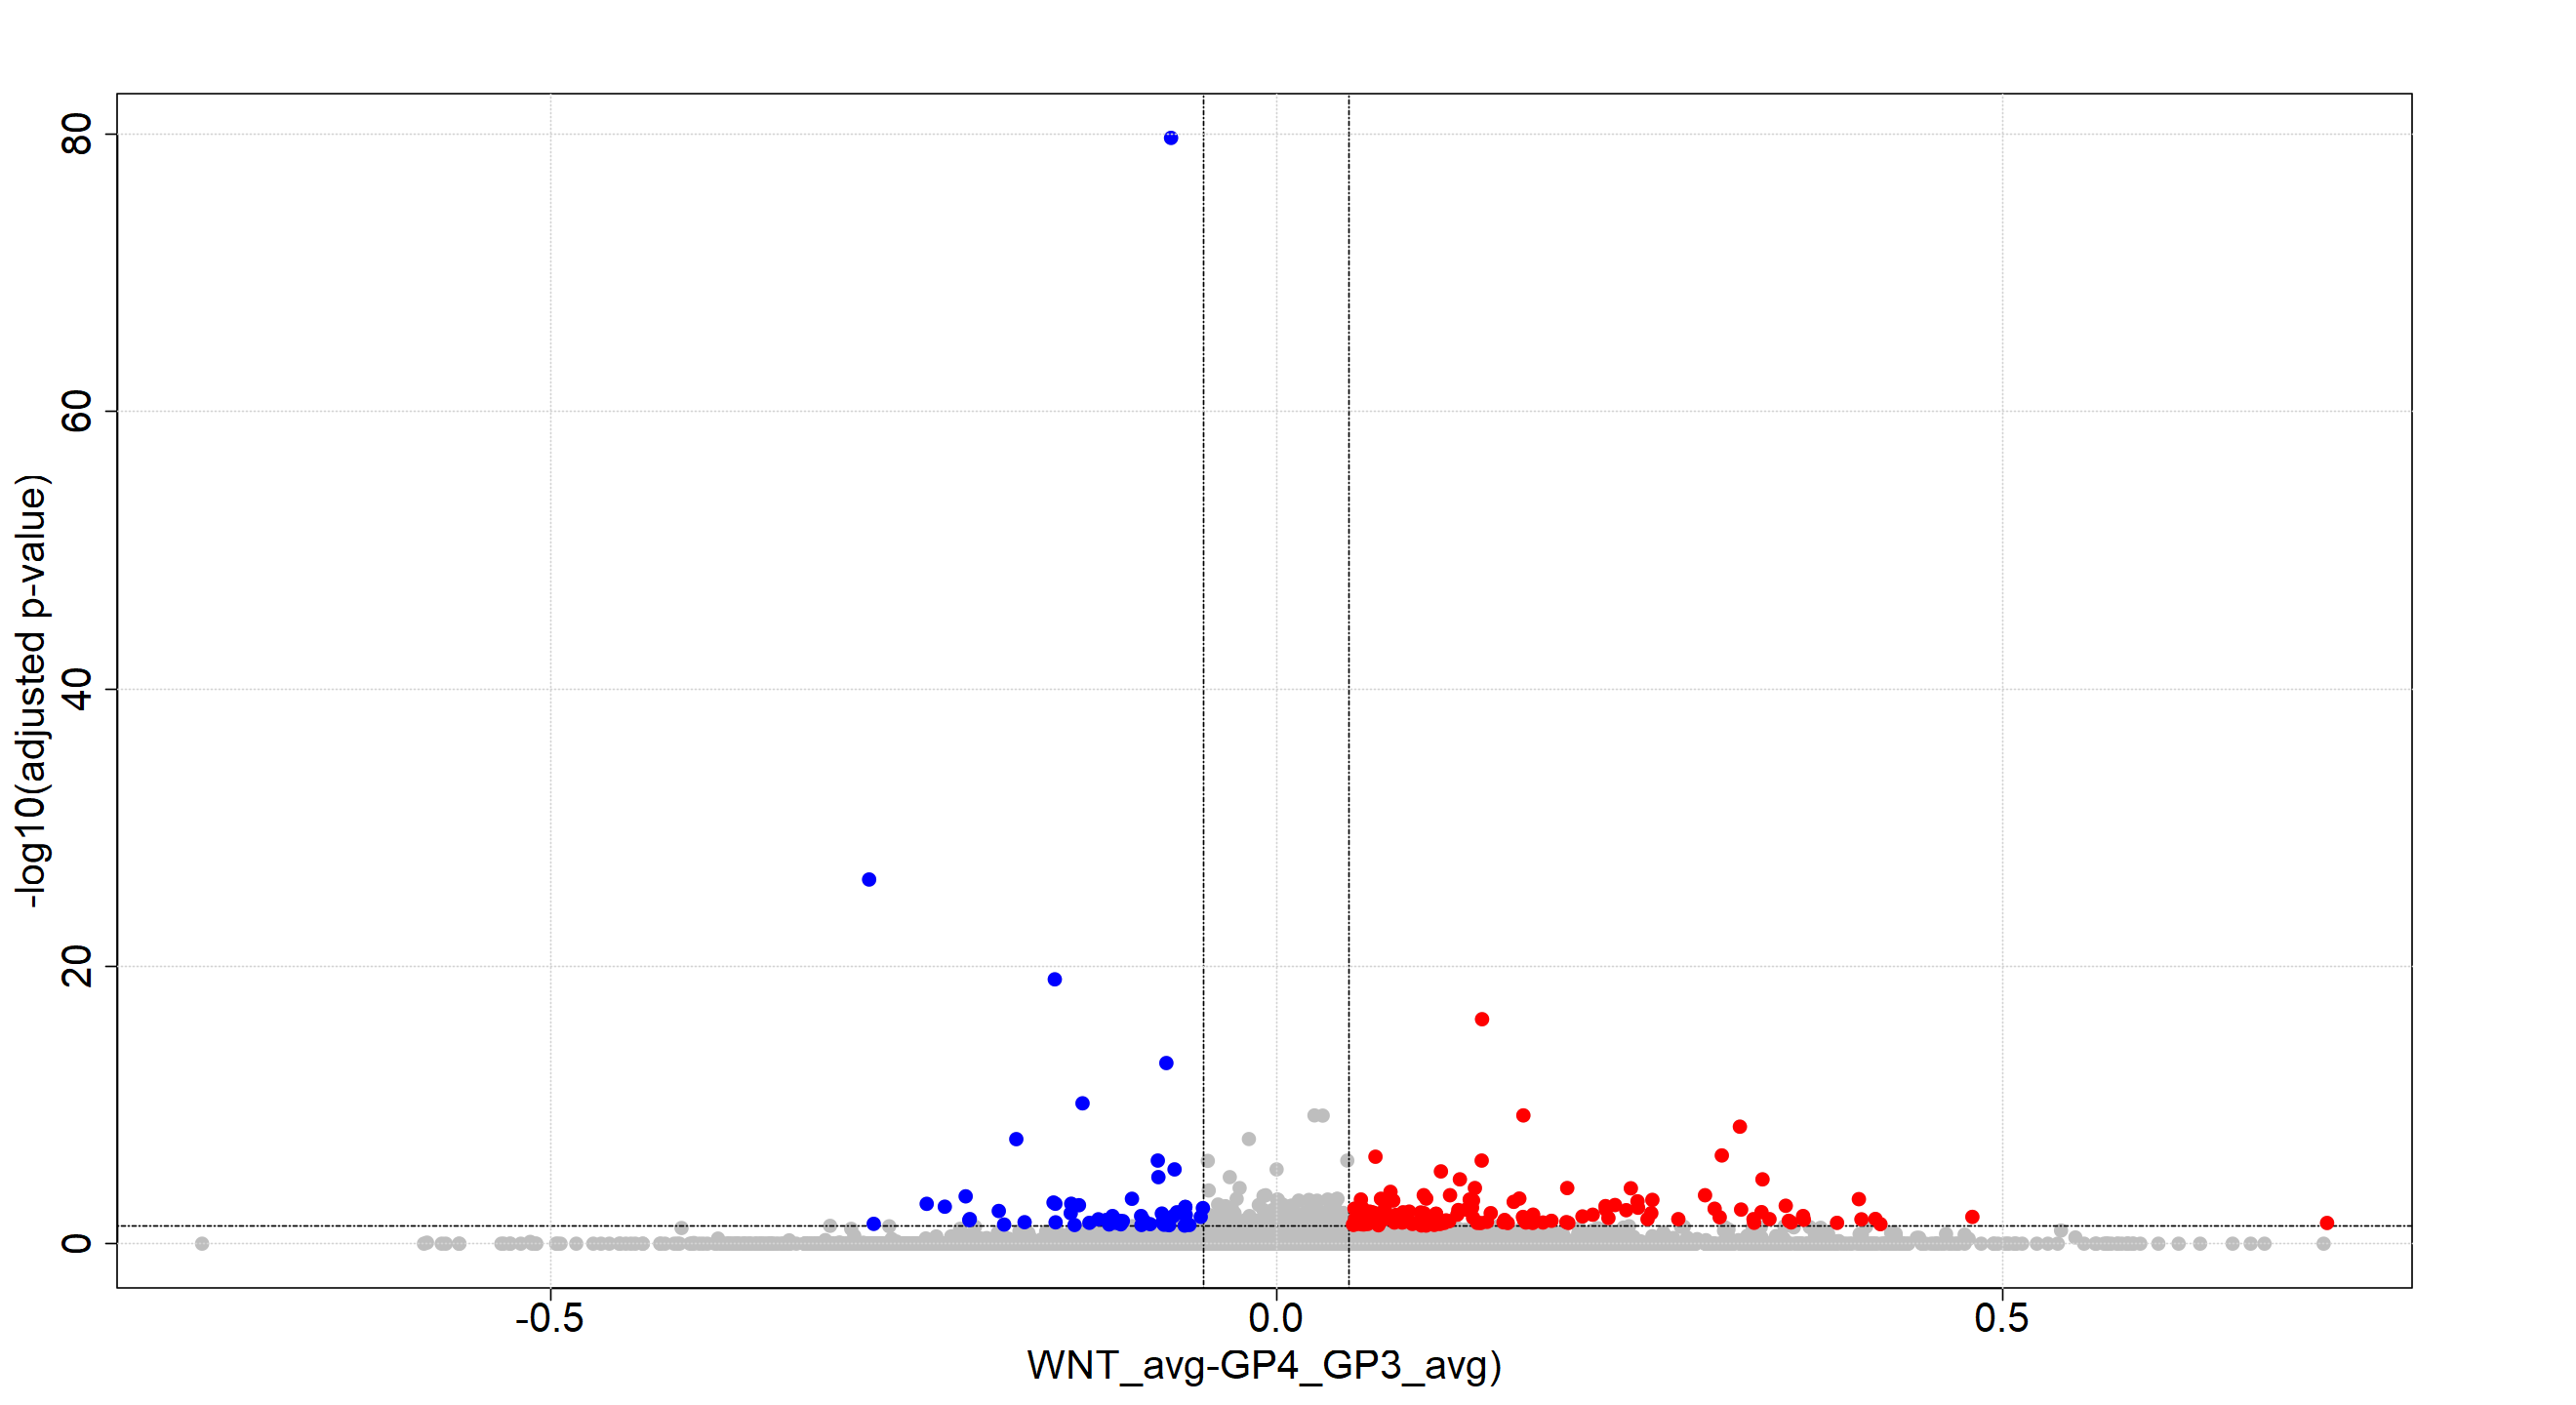

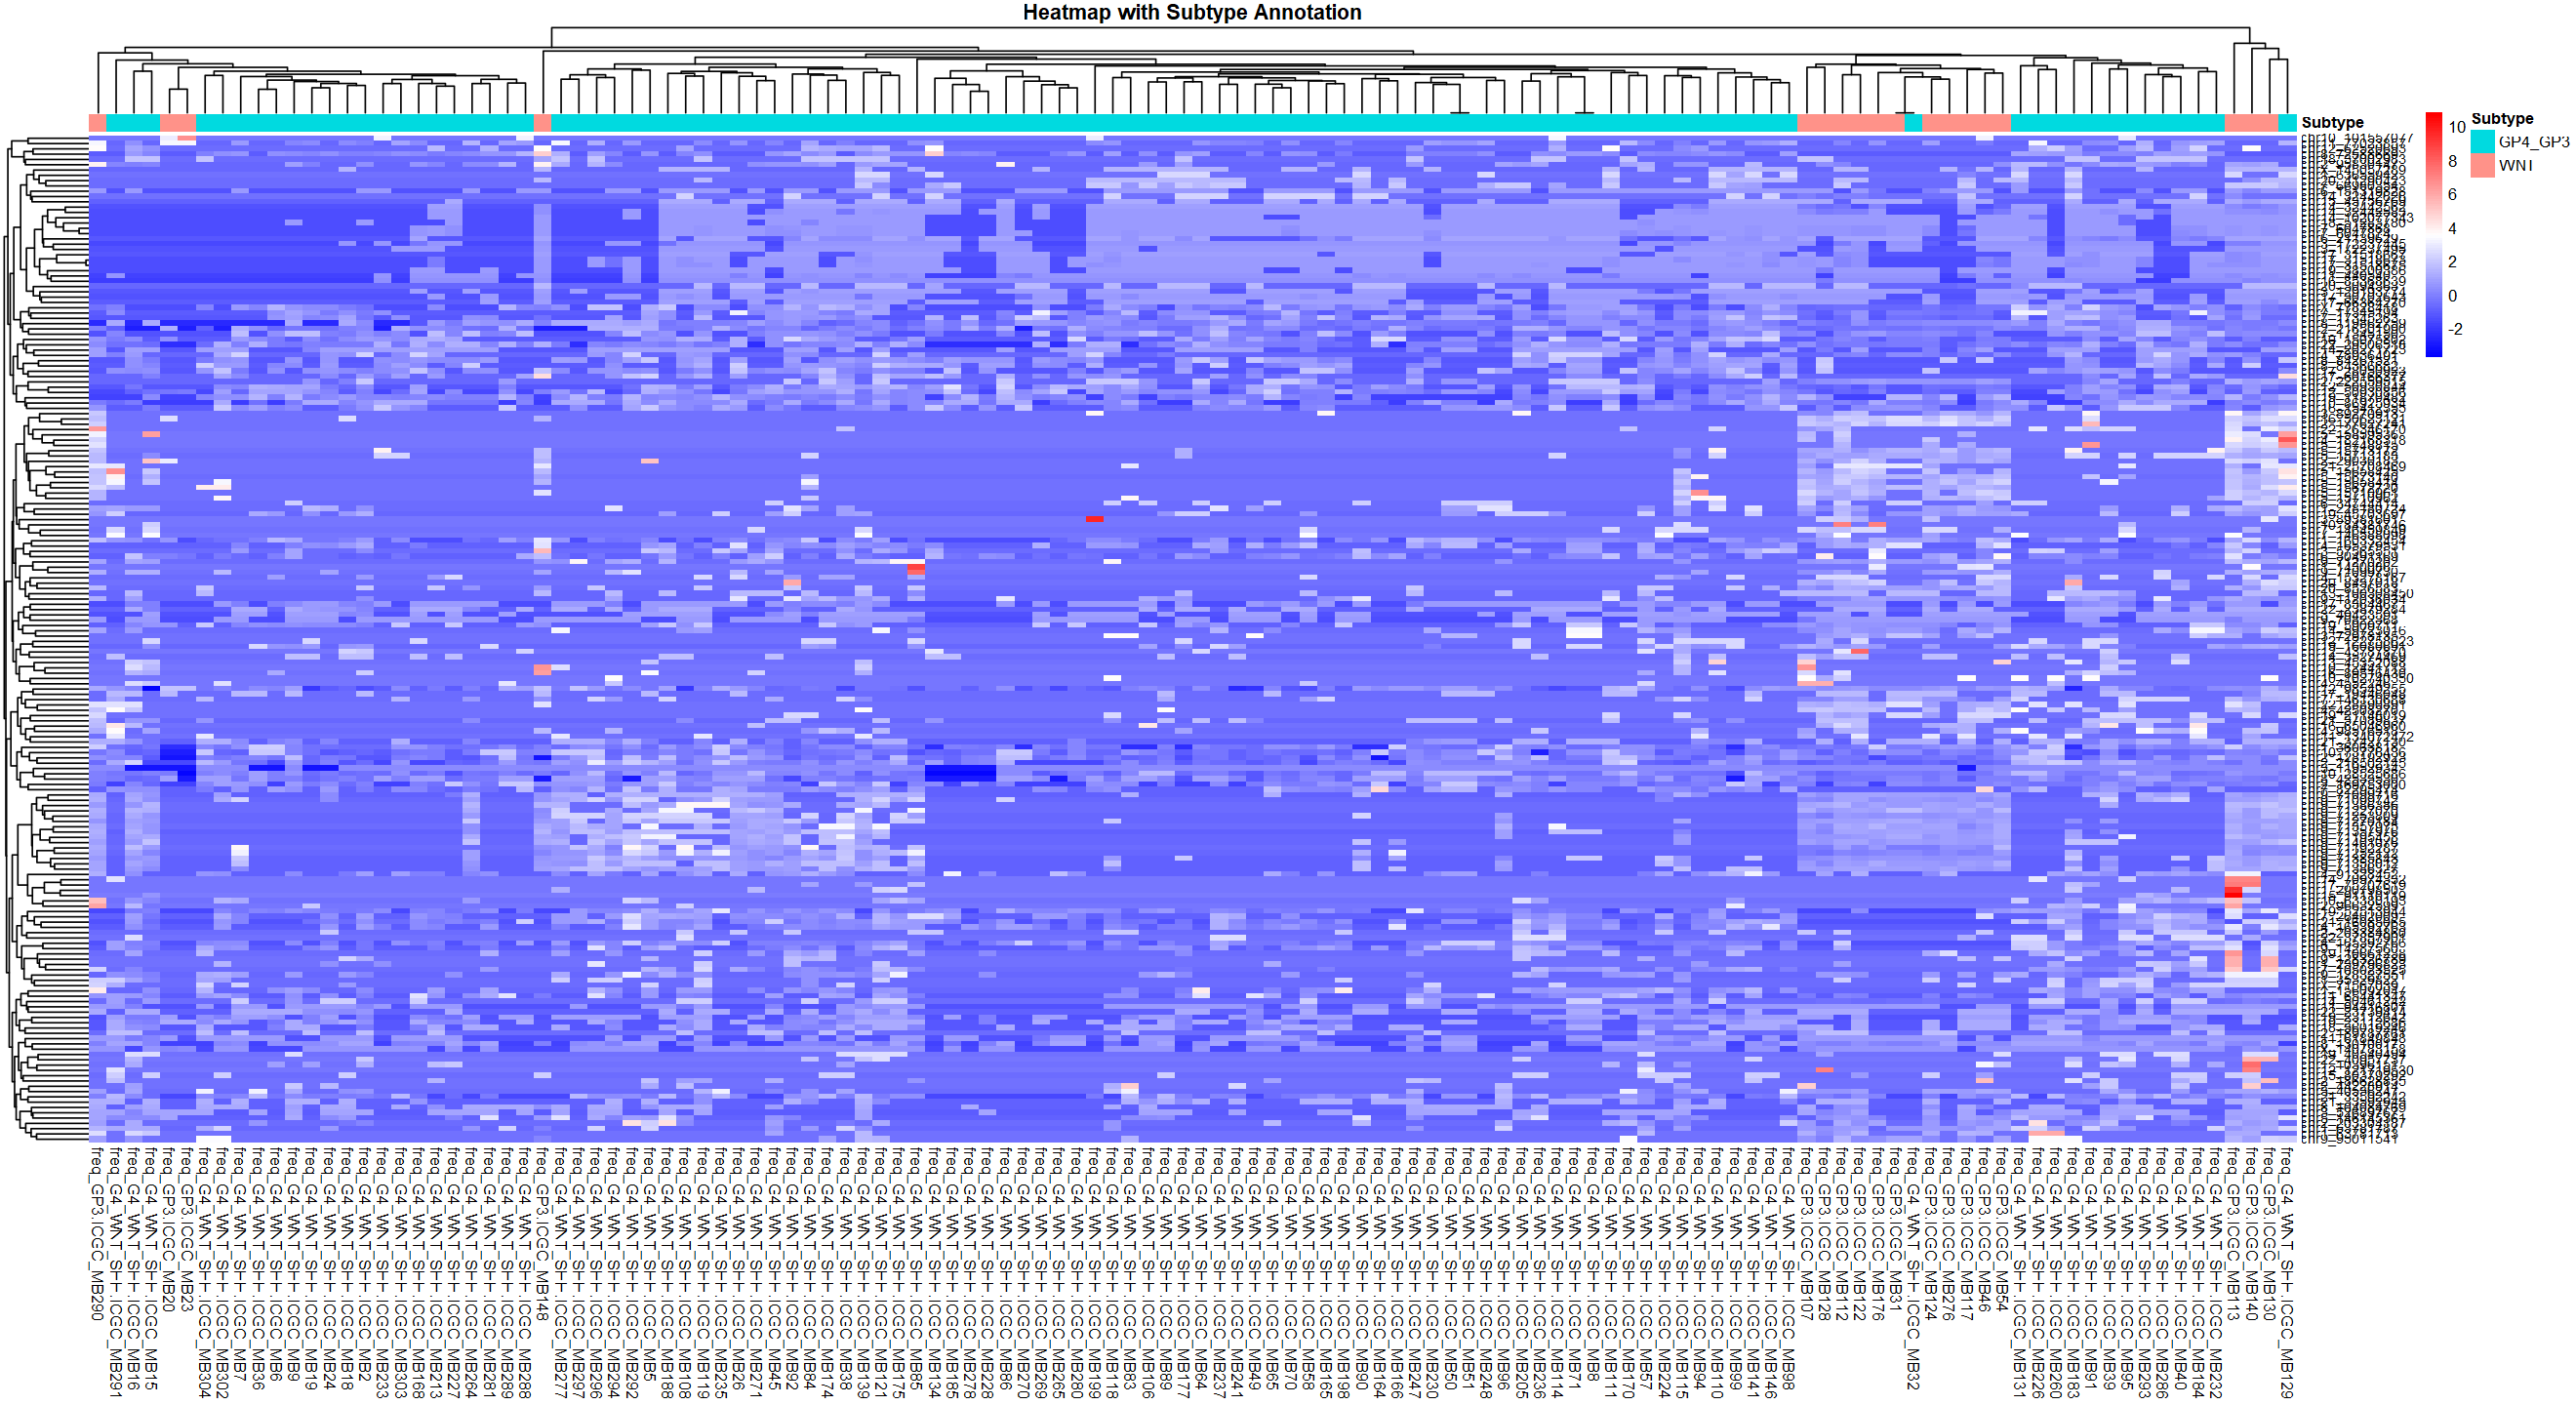

In [ ]:
Diff_editing(df1_Ref = SHH_Ref, df1_Alt= SHH_Alt,df2_Ref = G4_WNT_G3_Ref, df2_Alt =G4_WNT_G3_Alt,group1 = "SHH", group2 = "G4_WNT_G3" )
Diff_editing(df1_Ref = WNT_Ref, df1_Alt= WNT_Alt,df2_Ref = SHH_G4_G3_Ref, df2_Alt =SHH_G4_G3_Alt,group1 = "WNT", group2 = "SHH_G4_G3" )
Diff_editing(df1_Ref = G3_Ref, df1_Alt= G3_Alt,df2_Ref = G4_WNT_SHH_Ref, df2_Alt =G4_WNT_SHH_Alt,group1 = "G3", group2 = "G4_WNT_SHH" )
Diff_editing(df1_Ref = G4_Ref, df1_Alt= G4_Alt,df2_Ref = SHH_WNT_G3_Ref, df2_Alt =SHH_WNT_G3_Alt,group1 = "G4", group2 = "SHH_WNT_G3" )
Diff_editing(df1_Ref = G4_Ref, df1_Alt= G4_Alt,df2_Ref = G3_Ref, df2_Alt =G3_Alt,group1 = "G4", group2 = "G3" )
Diff_editing(df1_Ref = SHH_Ref, df1_Alt= SHH_Alt,df2_Ref = G4_G3_Ref, df2_Alt =G4_G3_Alt,group1 = "SHH", group2 = "GP4_GP3" )
Diff_editing(df1_Ref = WNT_Ref, df1_Alt= WNT_Alt,df2_Ref = G4_G3_Ref, df2_Alt =G4_G3_Alt,group1 = "WNT", group2 = "GP4_GP3" )